# Machine Learning

S1-26 AIMLZG565

Wrishav Sett

2026AJ05786

## Breast Cancer Diagnosis: Comparing Five Classification Models

This notebook trains and evaluates five classifiers on the Breast Cancer Wisconsin (Diagnostic) dataset and saves everything the Streamlit app needs: the trained models, the held-out test data and the metadata that connects them.

**Ground rules followed throughout**

- Malignant is the positive class (M = 1, B = 0) in the encoding, the metrics and every plot.
- Feature names are fixed once and shared by this notebook, `test_data.csv` and the Streamlit app.
- One random seed is passed explicitly to every split, fold and model that involves randomness.
- The test set is used only for the final evaluation, never for training or tuning.

## Section 0: Setup and Configuration

In [1]:
# Install the required packages (run once, then restart the kernel)
%pip install -q \
    joblib==1.6.0 \
    matplotlib==3.11.2 \
    numpy==2.4.6 \
    pandas==3.1.0 \
    scikit-learn==1.9.1 \
    seaborn==0.13.2 \
    streamlit==1.66.1 \
    ucimlrepo==0.0.7

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Render every plot inline, directly below the cell that draws it
%matplotlib inline

# Standard library
import json
import platform
import textwrap
import time
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import seaborn as sns

# Model persistence
import joblib

# scikit-learn: splitting, tuning and validation
import sklearn
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)

# scikit-learn: preprocessing, projection and models
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# scikit-learn: evaluation
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

print("Libraries imported.")

Libraries imported.


In [3]:
# Reproducibility: one seed, passed explicitly everywhere (taken from student ID 2026AJ05786)
RANDOM_STATE = 786

# Split and cross-validation settings
TEST_SIZE = 0.2
CV_FOLDS = 5

# Target definition: malignant is the positive class
TARGET = "diagnosis"
LABEL_MAP = {"M": 1, "B": 0}
INVERSE_LABEL_MAP = {value: key for key, value in LABEL_MAP.items()}
CLASS_NAMES = ["Benign (0)", "Malignant (1)"]

# Output locations, relative to the repository root
MODEL_DIR = Path("model")
TEST_DATA_PATH = Path("test_data.csv")
REQUIREMENTS_PATH = Path("requirements.txt")
MODEL_DIR.mkdir(exist_ok=True)

# Plot colours: a colour-blind safe categorical order, one colour per class and per model
CLASS_COLOURS = {"B": "#2a78d6", "M": "#eb6834"}
MODEL_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
NEUTRAL_COLOUR = "#898781"

# Shared plot styling: light grid and muted axes so the data stands out
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titleweight": "bold",
    "grid.color": "#e1e0d9",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.color": "#0b0b0b",
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)

print(f"Random state: {RANDOM_STATE}, test size: {TEST_SIZE}, CV folds: {CV_FOLDS}")

Random state: 786, test size: 0.2, CV folds: 5


In [4]:
def get_environment_versions():
    """Collect the Python and library versions used in this run.

    Returns
    -------
    dict
        Mapping of package name to version string. The library entries are
        used in Section 11 to pin requirements.txt for deployment.
    """
    return {
        "python": platform.python_version(),
        "scikit-learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "matplotlib": matplotlib.__version__,
        "seaborn": sns.__version__,
        "joblib": joblib.__version__,
    }


# Print the versions; Section 11 pins them in requirements.txt
ENV_VERSIONS = get_environment_versions()
for package, version in ENV_VERSIONS.items():
    print(f"{package:<14} {version}")

python         3.11.2
scikit-learn   1.9.1
pandas         3.1.0
numpy          2.4.6
matplotlib     3.11.2
seaborn        0.13.2
joblib         1.6.0


## Section 1: Dataset Loading and Inspection

**Dataset:** Breast Cancer Wisconsin (Diagnostic), UCI Machine Learning Repository, dataset id 17.

The data is loaded with `ucimlrepo`. If the download fails, the notebook falls back to the identical copy bundled with scikit-learn. The two sources name their columns differently, so both are renamed to one readable scheme (`radius_mean`, `radius_se`, `radius_worst`, and so on). These names are the contract between this notebook, `test_data.csv` and the Streamlit app.

**Dataset description**

- 569 samples, 30 numeric features, no missing values.
- Target: diagnosis, malignant (M, 212 samples) or benign (B, 357 samples).
- The features are computed from a digitised image of a fine needle aspirate (FNA) of a breast mass. Ten characteristics of the cell nuclei are measured, and each is recorded three ways: the mean across nuclei (`_mean`), its standard error (`_se`) and the mean of the three largest values (`_worst`).

| Characteristic | What it measures |
|---|---|
| radius | Mean distance from the centre to points on the perimeter |
| texture | Standard deviation of grey-scale values |
| perimeter | Perimeter of the nucleus |
| area | Area of the nucleus |
| smoothness | Local variation in radius lengths |
| compactness | perimeter^2 / area - 1.0 |
| concavity | Severity of concave portions of the contour |
| concave_points | Number of concave portions of the contour |
| symmetry | Symmetry of the nucleus |
| fractal_dimension | Coastline approximation - 1 |

In [5]:
def load_breast_cancer_data():
    """Load the Breast Cancer Wisconsin (Diagnostic) dataset.

    The UCI ML Repository (dataset id 17) is tried first. If that fails,
    for example because the machine has no internet access, the identical
    copy bundled with scikit-learn is used instead.

    Returns
    -------
    X : pandas.DataFrame
        The 30 numeric features in the original UCI column order.
    y : pandas.Series
        Diagnosis labels, "M" (malignant) or "B" (benign).
    source : str
        Description of where the data was loaded from.
    """
    try:
        from ucimlrepo import fetch_ucirepo

        dataset = fetch_ucirepo(id=17)
        X = dataset.data.features.copy()
        y = dataset.data.targets.iloc[:, 0].astype(str)
        source = "UCI Machine Learning Repository (id 17)"
    except Exception as error:
        print(f"UCI download failed ({error}). Using the scikit-learn copy of the same data.")
        from sklearn.datasets import load_breast_cancer

        bunch = load_breast_cancer(as_frame=True)
        X = bunch.data.copy()
        # scikit-learn encodes 0 = malignant and 1 = benign
        y = bunch.target.map({0: "M", 1: "B"})
        source = "UCI Breast Cancer Wisconsin (Diagnostic), scikit-learn bundled copy"
    return X.reset_index(drop=True), y.reset_index(drop=True), source

In [6]:
# Readable feature names: 10 nucleus characteristics x 3 statistics
BASE_FEATURES = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry", "fractal_dimension",
]
FEATURE_NAMES = [f"{base}_{stat}" for stat in ("mean", "se", "worst") for base in BASE_FEATURES]

X_raw, y_raw, DATA_SOURCE = load_breast_cancer_data()

# Both sources list the columns in the same order, so rename by position
assert X_raw.shape == (569, 30), f"Unexpected feature shape: {X_raw.shape}"
X_raw.columns = FEATURE_NAMES
y_raw = y_raw.rename(TARGET)

# Spot-check the column order against known values of the first sample
first_row = X_raw.iloc[0]
assert np.isclose(first_row["radius_mean"], 17.99), "Column order check failed (mean)"
assert np.isclose(first_row["radius_se"], 1.095), "Column order check failed (se)"
assert np.isclose(first_row["radius_worst"], 25.38), "Column order check failed (worst)"
assert set(y_raw.unique()) == {"M", "B"}, "Target must contain only M and B"

print(f"Loaded from : {DATA_SOURCE}")
print(f"Samples     : {X_raw.shape[0]}")
print(f"Features    : {X_raw.shape[1]}")

Loaded from : UCI Machine Learning Repository (id 17)
Samples     : 569
Features    : 30


### 1.1 Feature matrix

Structure, data types, missing values, duplicates and summary statistics of the 30 features.

In [7]:
# Structure and quality checks on the feature matrix
dtype_counts = {str(dtype): int(count) for dtype, count in X_raw.dtypes.value_counts().items()}
print(f"Shape          : {X_raw.shape}")
print(f"Data types     : {dtype_counts}")
print(f"Missing values : {int(X_raw.isnull().sum().sum())}")
print(f"Duplicate rows : {int(X_raw.duplicated().sum())}")
display(X_raw.head())

Shape          : (569, 30)
Data types     : {'float64': 30}
Missing values : 0
Duplicate rows : 0


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [8]:
# Summary statistics, transposed so that each feature is a row
display(X_raw.describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
texture_mean,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
perimeter_mean,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
area_mean,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
smoothness_mean,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
compactness_mean,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
concavity_mean,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
concave_points_mean,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
symmetry_mean,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040
fractal_dimension_mean,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974


### 1.2 Target

Class counts and percentages of the diagnosis column.

In [9]:
# Class distribution of the target
target_summary = pd.DataFrame({
    "count": y_raw.value_counts(),
    "percent": (y_raw.value_counts(normalize=True) * 100).round(2),
})
display(target_summary)
print(f"Missing target values: {int(y_raw.isnull().sum())}")

,count,percent
diagnosis,,
B,357,62.74
M,212,37.26


Missing target values: 0


### 1.3 Problem statement

A short dataset summary and the problem statement, both reused in the README.

In [10]:
# Dataset summary and problem statement (reused in the README)
DATASET_INFO = {
    "name": "Breast Cancer Wisconsin (Diagnostic)",
    "source": DATA_SOURCE,
    "n_samples": int(X_raw.shape[0]),
    "n_features": int(X_raw.shape[1]),
    "problem_type": "Binary classification",
    "positive_class": "Malignant (M = 1)",
}

PROBLEM_STATEMENT = (
    "Predict whether a breast mass is malignant or benign from 30 measurements of cell "
    "nuclei taken from a fine needle aspirate image. Five classification models are "
    "trained and compared on the same data, and the trained models are deployed in a "
    "Streamlit app that evaluates them on held-out test data."
)

for key, value in DATASET_INFO.items():
    print(f"{key:<15}: {value}")
print("\nProblem statement:")
print(textwrap.fill(PROBLEM_STATEMENT, width=100))

name           : Breast Cancer Wisconsin (Diagnostic)
source         : UCI Machine Learning Repository (id 17)
n_samples      : 569
n_features     : 30
problem_type   : Binary classification
positive_class : Malignant (M = 1)

Problem statement:
Predict whether a breast mass is malignant or benign from 30 measurements of cell nuclei taken from
a fine needle aspirate image. Five classification models are trained and compared on the same data,
and the trained models are deployed in a Streamlit app that evaluates them on held-out test data.


## Section 2: Exploratory Data Analysis

This section looks at the data before any modelling: how balanced the classes are, how different the feature scales are, which features are redundant, which ones separate the two classes, and how separable the classes are overall. Each plot is followed by a short note on what it shows and how it shapes the modelling choices.

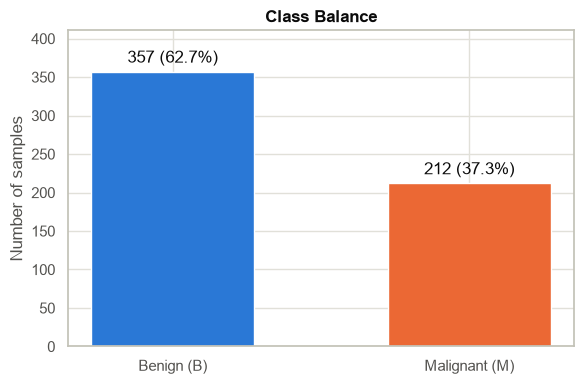

In [11]:
# Class balance: counts and percentages per diagnosis
class_counts = y_raw.value_counts().reindex(["B", "M"])

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ["Benign (B)", "Malignant (M)"],
    class_counts.values,
    color=[CLASS_COLOURS["B"], CLASS_COLOURS["M"]],
    width=0.55,
)
for bar, count in zip(bars, class_counts.values):
    ax.annotate(
        f"{count} ({count / len(y_raw):.1%})",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom", xytext=(0, 4), textcoords="offset points",
    )
ax.set_ylabel("Number of samples")
ax.set_title("Class Balance")
ax.set_ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()

**Note:** The classes are moderately imbalanced, with roughly 63% benign and 37% malignant. That is not severe enough to need resampling, but a model could score well on accuracy while still misclassifying many malignant cases. The split is therefore stratified, and precision, recall, F1 and MCC are reported alongside accuracy.

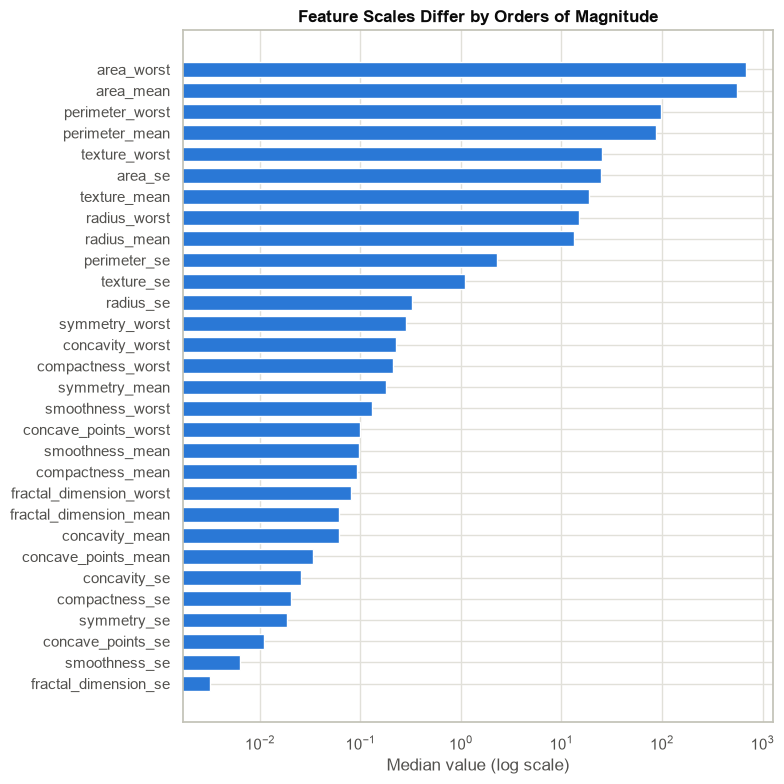

Largest median  : area_worst = 686.50
Smallest median : fractal_dimension_se = 0.00319
Ratio           : 215,406 times


In [12]:
# Median of each feature on a log scale, to show how different the scales are
feature_medians = X_raw.median().sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(feature_medians.index, feature_medians.values, color="#2a78d6", height=0.7)
ax.set_xscale("log")
ax.set_xlabel("Median value (log scale)")
ax.set_title("Feature Scales Differ by Orders of Magnitude")
plt.tight_layout()
plt.show()

print(f"Largest median  : {feature_medians.idxmax()} = {feature_medians.max():.2f}")
print(f"Smallest median : {feature_medians.idxmin()} = {feature_medians.min():.5f}")
print(f"Ratio           : {feature_medians.max() / feature_medians.min():,.0f} times")

**Note:** The area features are in the hundreds while several standard error features are in the thousandths. Without scaling, KNN and the SVM would measure distance almost entirely through the area features, and regularised logistic regression would penalise coefficients unevenly. Every model is therefore wrapped in a pipeline that standardises the features using statistics learned from the training data only (Section 4).

### 2.1 Correlation matrix

The full Pearson correlation matrix of the 30 features, with every coefficient printed in its cell. Red cells are positive correlations, blue cells negative, and the diagonal is always 1.

In [13]:
def top_correlated_pairs(corr_matrix, threshold=0.95):
    """List feature pairs whose absolute correlation exceeds a threshold.

    Parameters
    ----------
    corr_matrix : pandas.DataFrame
        Square correlation matrix of the features.
    threshold : float, default 0.95
        Minimum absolute correlation for a pair to be reported.

    Returns
    -------
    pandas.DataFrame
        One row per pair with columns feature_a, feature_b and correlation,
        sorted by absolute correlation, highest first.
    """
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
    pairs = upper.stack().dropna().reset_index()
    pairs.columns = ["feature_a", "feature_b", "correlation"]
    strong = pairs[pairs["correlation"].abs() > threshold]
    return strong.sort_values("correlation", key=np.abs, ascending=False).reset_index(drop=True)

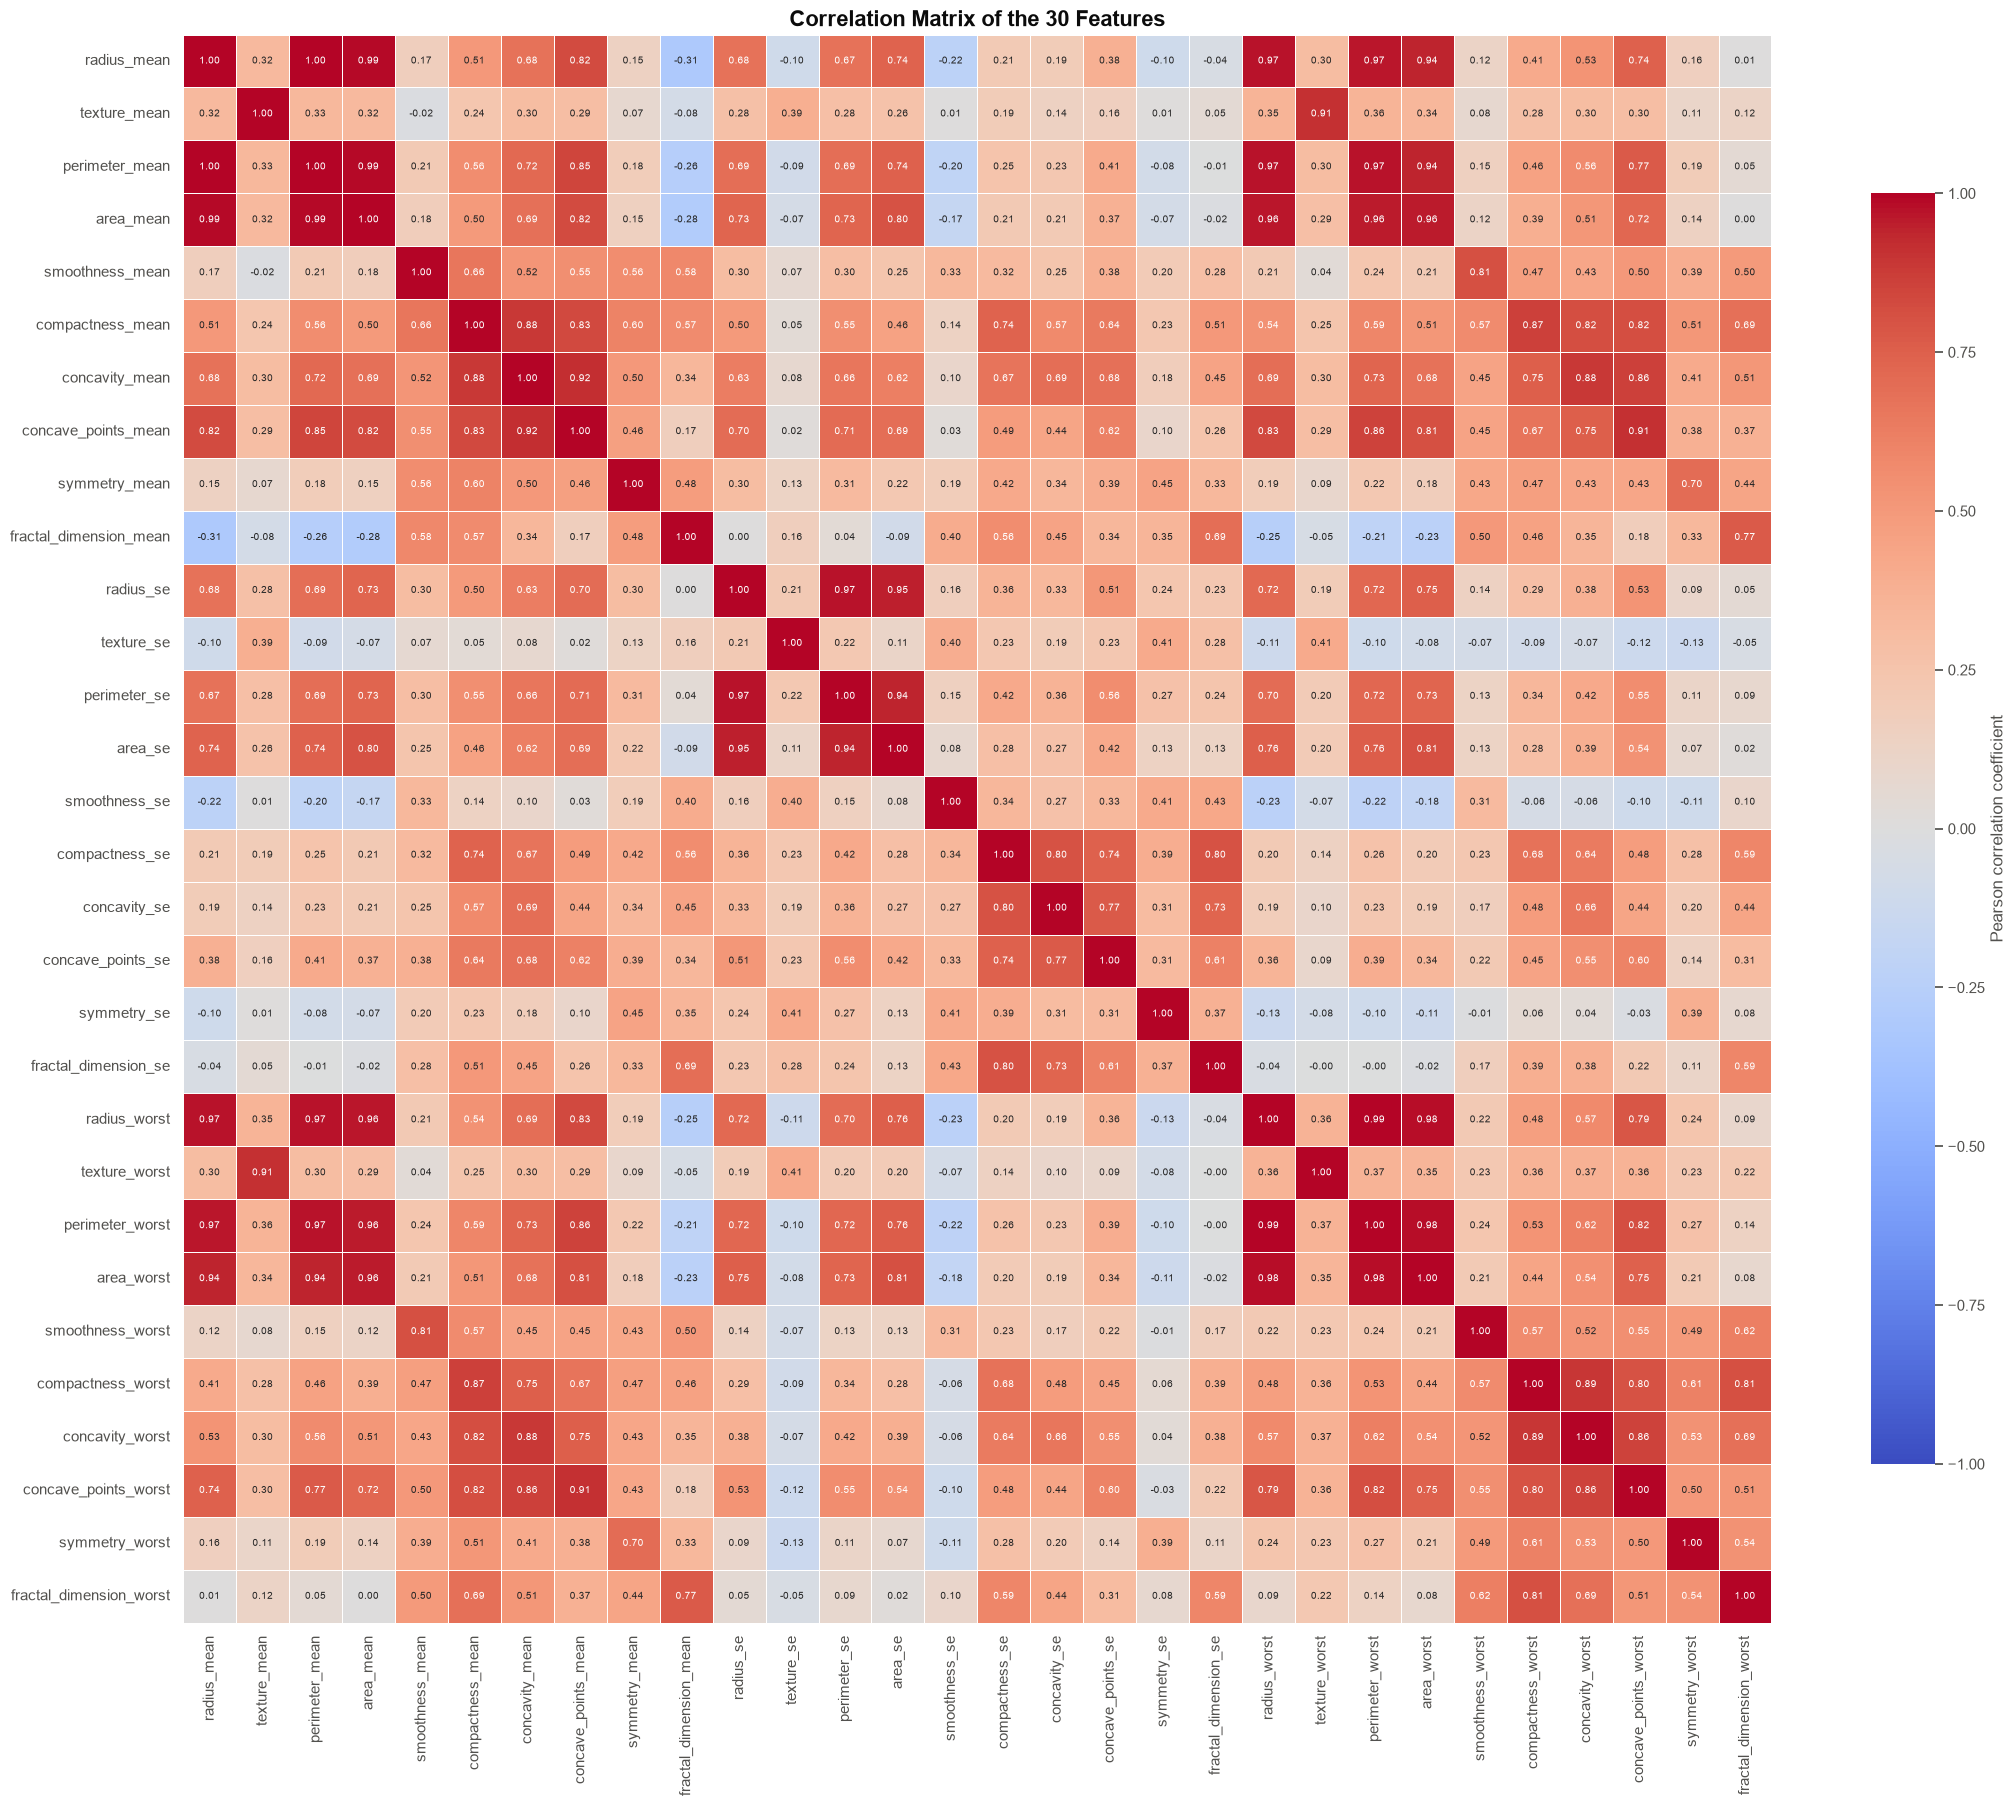

Feature pairs with absolute correlation above 0.95: 15


,feature_a,feature_b,correlation
0,radius_mean,perimeter_mean,0.9979
1,radius_worst,perimeter_worst,0.9937
2,radius_mean,area_mean,0.9874
3,perimeter_mean,area_mean,0.9865
4,radius_worst,area_worst,0.9840
5,perimeter_worst,area_worst,0.9776
6,radius_se,perimeter_se,0.9728
7,perimeter_mean,perimeter_worst,0.9704
8,radius_mean,radius_worst,0.9695
9,perimeter_mean,radius_worst,0.9695


In [14]:
# Full Pearson correlation matrix with every coefficient annotated
corr = X_raw.corr()

fig, ax = plt.subplots(figsize=(22, 18))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5, annot_kws={"size": 7},
    cbar_kws={"shrink": 0.8, "label": "Pearson correlation coefficient"}, ax=ax,
)
ax.set_title("Correlation Matrix of the 30 Features", fontsize=16)
ax.tick_params(axis="x", rotation=90)
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

# The most redundant pairs, read from the same matrix
strong_pairs = top_correlated_pairs(corr, threshold=0.95)
print(f"Feature pairs with absolute correlation above 0.95: {len(strong_pairs)}")
display(strong_pairs.round(4))

**Note:** Radius, perimeter and area are almost perfectly correlated with each other, which is expected because perimeter and area are geometric functions of the radius. The same block appears for the `_mean`, `_se` and `_worst` versions. This redundancy matters for the models:

- Naive Bayes assumes the features are independent given the class, so it effectively counts the same size evidence several times.
- Logistic regression coefficients become unstable when features are collinear; L2 regularisation (tuned through C) keeps them in check.
- Decision trees pick one feature from a correlated group more or less arbitrarily, which can make them unstable.

All 30 features are kept so that all five models are compared on exactly the same input, and so that the app accepts the full test file.

### 2.2 Relationship with the target

Which features differ most between benign and malignant samples.

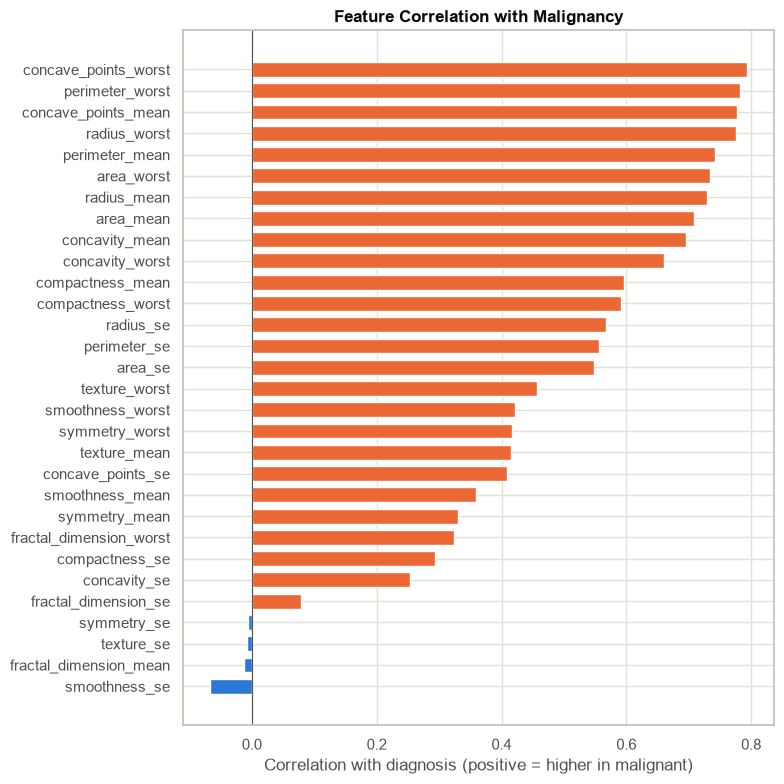

In [15]:
# Correlation of each feature with the target (malignant = 1)
y_numeric = y_raw.map(LABEL_MAP)
target_corr = X_raw.corrwith(y_numeric).sort_values()

fig, ax = plt.subplots(figsize=(8, 8))
bar_colours = [CLASS_COLOURS["M"] if value > 0 else CLASS_COLOURS["B"] for value in target_corr.values]
ax.barh(target_corr.index, target_corr.values, color=bar_colours, height=0.7)
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel("Correlation with diagnosis (positive = higher in malignant)")
ax.set_title("Feature Correlation with Malignancy")
plt.tight_layout()
plt.show()

### 2.3 Class separability

Two views of how well the classes separate: a scatter plot of the two features most correlated with the diagnosis, and a two-dimensional PCA projection of all 30 standardised features. The PCA here is for visualisation only and is not used by any model.

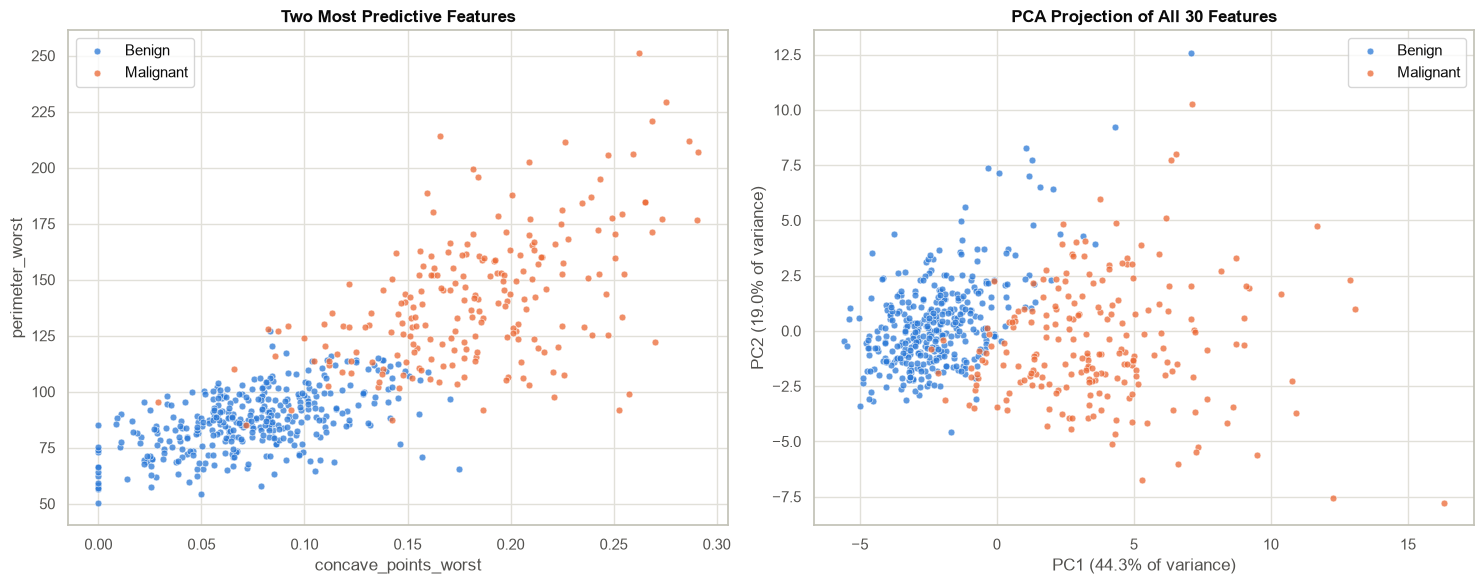

Variance explained by the first two components: 63.2%


In [16]:
# Scatter of the two most predictive features, and a 2D PCA projection of all features
ranked_features = target_corr.abs().sort_values(ascending=False)
top_two = list(ranked_features.index[:2])
scaled_all = StandardScaler().fit_transform(X_raw)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
components = pca.fit_transform(scaled_all)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for label, class_name in (("B", "Benign"), ("M", "Malignant")):
    is_class = (y_raw == label).values
    point_style = {
        "s": 24, "alpha": 0.75, "color": CLASS_COLOURS[label],
        "edgecolor": "white", "linewidth": 0.5, "label": class_name,
    }
    axes[0].scatter(X_raw.loc[is_class, top_two[0]], X_raw.loc[is_class, top_two[1]], **point_style)
    axes[1].scatter(components[is_class, 0], components[is_class, 1], **point_style)

axes[0].set_xlabel(top_two[0])
axes[0].set_ylabel(top_two[1])
axes[0].set_title("Two Most Predictive Features")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
axes[1].set_title("PCA Projection of All 30 Features")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

print(f"Variance explained by the first two components: {pca.explained_variance_ratio_[:2].sum():.1%}")

**Note:** Even in two dimensions the classes form two largely distinct groups, with a narrow region of overlap. A roughly straight boundary already separates most samples, so linear models such as logistic regression and a linear SVM are expected to do well, and differences between the five models are likely to be small. The samples in the overlap region are where the models will disagree.

## Section 3: Preprocessing, Train/Test Split and Test File

Steps in this section:

1. Encode the target with malignant as the positive class (M = 1, B = 0) and confirm the encoding with an assertion.
2. Confirm that there is nothing to impute.
3. Split the data 80/20, stratified by diagnosis, so that both sets keep the original class ratio.
4. Save the test portion as `test_data.csv` (all 30 features plus the original M/B labels) and verify it by reading it back.
5. Save the feature list and the label mapping to `model/` for the Streamlit app.

Scaling is deliberately not done here. It happens inside each model pipeline (Section 4), so the scaler is fitted on training data only, including inside every cross-validation fold, and is saved together with each model.

In [17]:
# Encode the target: malignant = 1 (positive class), benign = 0
X = X_raw.copy()
y = y_raw.map(LABEL_MAP).astype(int)

# Guard against a label flip: this dataset has 212 malignant samples
assert (y == 1).sum() == (y_raw == "M").sum() == 212, "Malignant must be encoded as 1"
print(f"Encoding      : {LABEL_MAP}")
print(f"Malignant (1) : {(y == 1).sum()}")
print(f"Benign (0)    : {(y == 0).sum()}")

# Section 1 found no missing values, so no imputation step is needed
assert X.isnull().sum().sum() == 0 and y.isnull().sum() == 0
print("Missing values: none, no imputation required.")

Encoding      : {'M': 1, 'B': 0}
Malignant (1) : 212
Benign (0)    : 357
Missing values: none, no imputation required.


In [18]:
# Stratified 80/20 split keeps the class ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame(
    {
        "samples": [len(y_train), len(y_test)],
        "benign (0)": [int((y_train == 0).sum()), int((y_test == 0).sum())],
        "malignant (1)": [int((y_train == 1).sum()), int((y_test == 1).sum())],
        "malignant %": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
    },
    index=["train", "test"],
)
display(split_summary)

,samples,benign (0),malignant (1),malignant %
train,455,285,170,37.36
test,114,72,42,36.84


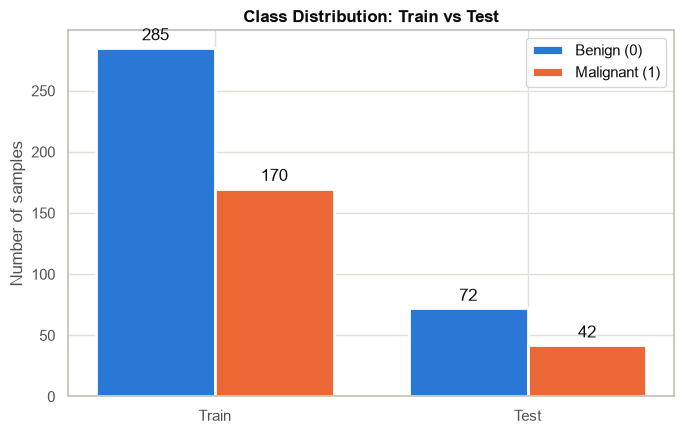

In [19]:
# Class counts in the training and test sets, coloured by class
set_names = ["Train", "Test"]
x_positions = np.arange(len(set_names))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(7, 4.5))
for offset, label, class_name in ((-bar_width / 2, "B", "Benign (0)"), (bar_width / 2, "M", "Malignant (1)")):
    counts = [int((part == LABEL_MAP[label]).sum()) for part in (y_train, y_test)]
    bars = ax.bar(
        x_positions + offset, counts, bar_width, label=class_name,
        color=CLASS_COLOURS[label], edgecolor="white", linewidth=2,
    )
    ax.bar_label(bars, padding=3)
ax.set_xticks(x_positions, set_names)
ax.set_ylabel("Number of samples")
ax.set_title("Class Distribution: Train vs Test")
ax.legend()
plt.tight_layout()
plt.show()

### 3.1 Saving `test_data.csv`

The test file holds the held-out 20% exactly as the models will see it in the app: the 30 feature columns in `FEATURE_NAMES` order, plus the `diagnosis` column with the original M/B labels. It is written once, from the same split that trains the saved models, so none of its rows were ever used for training or tuning.

In [20]:
def save_test_file(X_part, y_part, path):
    """Save a held-out split as the CSV that is uploaded to the Streamlit app.

    Labels are written back in their original form (M/B) so the file looks
    like the source data; the app converts them with the same LABEL_MAP.

    Parameters
    ----------
    X_part : pandas.DataFrame
        Feature columns named with FEATURE_NAMES.
    y_part : pandas.Series
        Encoded labels (1 = malignant, 0 = benign), aligned with X_part.
    path : pathlib.Path
        Destination CSV path.

    Returns
    -------
    pandas.DataFrame
        The frame that was written to disk.
    """
    test_frame = X_part[FEATURE_NAMES].copy()
    test_frame[TARGET] = y_part.map(INVERSE_LABEL_MAP)
    # index=False avoids an extra unnamed index column in the file
    test_frame.to_csv(path, index=False)
    return test_frame


def verify_test_file(path, X_part, y_part):
    """Read the saved test CSV back and check it matches the in-memory split.

    Parameters
    ----------
    path : pathlib.Path
        CSV written by save_test_file.
    X_part : pandas.DataFrame
        Expected feature values.
    y_part : pandas.Series
        Expected encoded labels.

    Raises
    ------
    AssertionError
        If the shape, column names, labels or values do not match.
    """
    reloaded = pd.read_csv(path)
    expected_shape = (len(X_part), len(FEATURE_NAMES) + 1)
    assert reloaded.shape == expected_shape, f"Unexpected shape {reloaded.shape}"
    assert list(reloaded.columns) == FEATURE_NAMES + [TARGET], "Column names or order differ"
    assert reloaded.isnull().sum().sum() == 0, "File contains missing values"
    assert (reloaded[TARGET].map(LABEL_MAP).values == y_part.values).all(), "Labels differ"
    assert np.allclose(reloaded[FEATURE_NAMES].values, X_part[FEATURE_NAMES].values), "Values differ"
    print(
        f"{path} verified: {reloaded.shape[0]} rows, {reloaded.shape[1]} columns, "
        f"{int((reloaded[TARGET] == 'M').sum())} malignant, {int((reloaded[TARGET] == 'B').sum())} benign."
    )

In [21]:
# Write the held-out test set and confirm it reads back identically
test_frame = save_test_file(X_test, y_test, TEST_DATA_PATH)
verify_test_file(TEST_DATA_PATH, X_test, y_test)
display(test_frame.head())

test_data.csv verified: 114 rows, 31 columns, 42 malignant, 72 benign.


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,diagnosis
381,11.04,14.93,70.67,372.7,0.07987,0.07079,0.03546,0.02074,0.2003,0.06246,0.1642,1.0310,1.281,11.68,0.005296,0.01903,0.01723,0.006960,0.01880,0.001941,12.09,20.83,79.73,447.1,0.1095,0.1982,0.1553,0.06754,0.3202,0.07287,B
13,15.85,23.95,103.70,782.7,0.08401,0.10020,0.09938,0.05364,0.1847,0.05338,0.4033,1.0780,2.903,36.58,0.009769,0.03126,0.05051,0.019920,0.02981,0.003002,16.84,27.66,112.00,876.5,0.1131,0.1924,0.2322,0.11190,0.2809,0.06287,M
86,14.48,21.46,94.25,648.2,0.09444,0.09947,0.12040,0.04938,0.2075,0.05636,0.4204,2.2200,3.301,38.87,0.009369,0.02983,0.05371,0.017610,0.02418,0.003249,16.21,29.25,108.40,808.9,0.1306,0.1976,0.3349,0.12250,0.3020,0.06846,M
94,15.06,19.83,100.30,705.6,0.10390,0.15530,0.17000,0.08815,0.1855,0.06284,0.4768,0.9644,3.706,47.14,0.009250,0.03715,0.04867,0.018510,0.01498,0.003520,18.23,24.23,123.50,1025.0,0.1551,0.4203,0.5203,0.21150,0.2834,0.08234,M
444,18.03,16.85,117.50,990.0,0.08947,0.12320,0.10900,0.06254,0.1720,0.05780,0.2986,0.5906,1.921,35.77,0.004117,0.01560,0.02975,0.009753,0.01295,0.002436,20.38,22.02,133.30,1292.0,0.1263,0.2666,0.4290,0.15350,0.2842,0.08225,M


In [22]:
def save_json(data, path):
    """Write a JSON-serialisable object to disk with readable indentation.

    Parameters
    ----------
    data : dict or list
        Object to save. Values JSON cannot encode are stored as strings.
    path : pathlib.Path
        Destination file.
    """
    with open(path, "w", encoding="utf-8") as handle:
        json.dump(data, handle, indent=2, default=str)


# Metadata the Streamlit app uses to validate and encode an uploaded file
save_json(FEATURE_NAMES, MODEL_DIR / "feature_names.json")
save_json(
    {"target": TARGET, "label_map": LABEL_MAP, "class_names": CLASS_NAMES},
    MODEL_DIR / "label_map.json",
)
print("Saved model/feature_names.json and model/label_map.json")

Saved model/feature_names.json and model/label_map.json


## Section 4: Model Pipelines

Every model is wrapped in the same two-step pipeline: `StandardScaler` followed by the classifier. This has three benefits:

- the scaler is fitted on training data only, including inside every cross-validation fold, so no information leaks from validation or test data;
- each saved model carries its own scaler, so the app can pass the raw CSV columns straight in;
- all five models share one interface, so the app treats them identically.

| Model | Notes |
|---|---|
| Logistic Regression | Linear decision boundary; `max_iter` raised so the solver converges |
| Decision Tree | Scale-invariant; the scaler is kept only for a uniform interface |
| KNN | Distance based, so scaling is essential |
| Naive Bayes (Gaussian) | Per-feature Gaussians; standardising has almost no effect, since only the var_smoothing term depends on feature scale |
| Support Vector Machine | AUC is computed from its decision function (Section 7), so probability calibration is not needed |

In [23]:
def build_pipeline(classifier):
    """Wrap a classifier in the standard scaling pipeline.

    Parameters
    ----------
    classifier : sklearn estimator
        Unfitted classifier placed after the scaler.

    Returns
    -------
    sklearn.pipeline.Pipeline
        Pipeline with the steps "scaler" (StandardScaler) and "clf" (the classifier).
    """
    return Pipeline([("scaler", StandardScaler()), ("clf", classifier)])


# Display names match the rows of the README comparison table
MODEL_NAMES = ["Logistic Regression", "Decision Tree", "KNN", "Naive Bayes", "Support Vector Machine"]
MODEL_COLOUR_MAP = dict(zip(MODEL_NAMES, MODEL_COLOURS))
# Vertical position of each model in the per-model comparison plots
MODEL_POSITIONS = np.arange(len(MODEL_NAMES))

base_pipelines = {
    "Logistic Regression": build_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    "Decision Tree": build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "KNN": build_pipeline(KNeighborsClassifier()),
    "Naive Bayes": build_pipeline(GaussianNB()),
    # SVC is deterministic without probability calibration, so it needs no random_state
    "Support Vector Machine": build_pipeline(SVC()),
}

for name, pipeline in base_pipelines.items():
    print(f"{name:<24} {pipeline.named_steps['clf']}")

Logistic Regression      LogisticRegression(max_iter=5000, random_state=786)
Decision Tree            DecisionTreeClassifier(random_state=786)
KNN                      KNeighborsClassifier()
Naive Bayes              GaussianNB()
Support Vector Machine   SVC()


## Section 5: Hyperparameter Tuning

Each pipeline is tuned with `GridSearchCV` on the **training set only**, using 5-fold stratified cross-validation.

**Tuning metric: MCC.** MCC uses all four cells of the confusion matrix and stays informative when the classes are imbalanced, whereas accuracy can look high while the minority class is handled poorly. It is therefore the objective used to choose hyperparameters.

**Class weights.** Logistic regression, the decision tree and the SVM are also allowed to choose `class_weight="balanced"`, which raises the cost of misclassifying the minority (malignant) class. The search decides whether that helps.

Hyperparameter names use the pipeline step prefix, so `clf__C` means "the parameter C of the step named clf".

| Model | Hyperparameters searched |
|---|---|
| Logistic Regression | C, class_weight |
| Decision Tree | max_depth, min_samples_leaf, criterion, class_weight |
| KNN | n_neighbors, weights, p (1 = Manhattan, 2 = Euclidean) |
| Naive Bayes | var_smoothing |
| Support Vector Machine | kernel (RBF or linear), C, gamma (RBF only), class_weight |

In [24]:
# Shared cross-validation splitter and tuning metric
cv_splitter = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
mcc_scorer = make_scorer(matthews_corrcoef)

# Search spaces; "clf__" targets the classifier step inside each pipeline
param_grids = {
    "Logistic Regression": {
        "clf__C": [0.01, 0.1, 1, 10, 100],
        "clf__class_weight": [None, "balanced"],
    },
    "Decision Tree": {
        "clf__max_depth": [3, 4, 5, 6, 8, None],
        "clf__min_samples_leaf": [1, 2, 5, 10],
        "clf__criterion": ["gini", "entropy"],
        "clf__class_weight": [None, "balanced"],
    },
    "KNN": {
        "clf__n_neighbors": [3, 5, 7, 9, 11, 15],
        "clf__weights": ["uniform", "distance"],
        "clf__p": [1, 2],
    },
    "Naive Bayes": {
        "clf__var_smoothing": np.logspace(-12, -3, 10),
    },
    # Two sub-grids so that gamma is only searched for the RBF kernel
    "Support Vector Machine": [
        {
            "clf__kernel": ["rbf"],
            "clf__C": [0.1, 1, 10, 100],
            "clf__gamma": ["scale", 0.01, 0.001],
            "clf__class_weight": [None, "balanced"],
        },
        {
            "clf__kernel": ["linear"],
            "clf__C": [0.01, 0.1, 1, 10],
            "clf__class_weight": [None, "balanced"],
        },
    ],
}

In [25]:
def tune_model(name, pipeline, param_grid):
    """Run a stratified grid search for one model on the training data.

    Parameters
    ----------
    name : str
        Display name of the model, used for the progress line.
    pipeline : sklearn.pipeline.Pipeline
        Unfitted scaler and classifier pipeline.
    param_grid : dict or list of dict
        Hyperparameter grid with "clf__" prefixed names.

    Returns
    -------
    sklearn.model_selection.GridSearchCV
        Fitted search object; best_estimator_ is refitted on the whole
        training set with the best parameters.
    """
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring=mcc_scorer,
        cv=cv_splitter,
        n_jobs=-1,
        refit=True,
    )
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    n_candidates = len(search.cv_results_["params"])
    print(f"{name:<24} {n_candidates:>3} candidates   best CV MCC {search.best_score_:.4f}   {elapsed:.1f} s")
    return search


# Tune every model; only the training set is used here
searches = {name: tune_model(name, base_pipelines[name], param_grids[name]) for name in MODEL_NAMES}
best_models = {name: search.best_estimator_ for name, search in searches.items()}

Logistic Regression       10 candidates   best CV MCC 0.9395   5.5 s
Decision Tree             96 candidates   best CV MCC 0.8729   1.9 s
KNN                       24 candidates   best CV MCC 0.9174   0.4 s
Naive Bayes               10 candidates   best CV MCC 0.8663   0.2 s
Support Vector Machine    32 candidates   best CV MCC 0.9535   0.6 s


In [26]:
def format_value(value):
    """Format a single hyperparameter value for tables and axis labels.

    Parameters
    ----------
    value : object
        A hyperparameter value: number, string or None.

    Returns
    -------
    str
        Very small floats in scientific notation, other numbers in their
        shortest form, and everything else as plain text.
    """
    if isinstance(value, float):
        return f"{value:.0e}" if value < 0.01 else f"{value:g}"
    return str(value)


def format_params(params):
    """Turn a best_params_ dictionary into a short readable string.

    Parameters
    ----------
    params : dict
        Parameters as returned by GridSearchCV.best_params_.

    Returns
    -------
    str
        Comma-separated name=value pairs with the "clf__" prefix removed.
    """
    return ", ".join(f"{key.replace('clf__', '')}={format_value(value)}" for key, value in params.items())


# Best hyperparameters per model (reported in the README)
best_params_table = pd.DataFrame({
    "best parameters": {name: format_params(search.best_params_) for name, search in searches.items()},
    "best CV MCC": {name: round(search.best_score_, 4) for name, search in searches.items()},
})
display(best_params_table)

# Saved so that the app can show the settings of the selected model
save_json(
    {name: {key.replace("clf__", ""): value for key, value in search.best_params_.items()}
     for name, search in searches.items()},
    MODEL_DIR / "best_params.json",
)

,best parameters,best CV MCC
Logistic Regression,"C=100, class_weight=None",0.9395
Decision Tree,"class_weight=None, criterion=gini, max_depth=4, min_samples_leaf=2",0.8729
KNN,"n_neighbors=15, p=2, weights=distance",0.9174
Naive Bayes,var_smoothing=1e-12,0.8663
Support Vector Machine,"C=10, class_weight=None, gamma=0.01, kernel=rbf",0.9535


### 5.1 Tuning curves

How the cross-validated MCC changes along the most influential hyperparameter of each model. Each line shows the best score reachable at each value of that hyperparameter (over all other settings in the grid), the shaded band is plus or minus one standard deviation across the folds, and the star marks the selected combination.

In [27]:
def ordering_key(value):
    """Sort key that orders numbers ascending, then text, then None.

    Parameters
    ----------
    value : object
        A hyperparameter value: number, string or None.

    Returns
    -------
    tuple
        Key that places numbers first (ascending), strings next and None last.
    """
    if value is None:
        return (2, 0.0, "")
    if isinstance(value, (int, float, np.integer, np.floating)):
        return (0, float(value), "")
    return (1, 0.0, str(value))


def plot_tuning_curve(ax, search, x_param, line_param, colour):
    """Plot cross-validated MCC against one hyperparameter of a grid search.

    For every value of x_param (and of line_param, when given) the best mean
    score over all other hyperparameters is plotted, with a band of plus or
    minus one standard deviation across folds.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        Axes to draw on.
    search : sklearn.model_selection.GridSearchCV
        Fitted grid search.
    x_param : str
        Hyperparameter shown on the x axis, without the "clf__" prefix.
    line_param : str or None
        Hyperparameter that splits the results into separate lines.
    colour : str
        Colour of the first line and of the selected-point marker.
    """
    results = search.cv_results_
    x_key = f"clf__{x_param}"
    line_key = f"clf__{line_param}" if line_param else None

    # Ordered x values; values are plotted at evenly spaced positions
    x_values = sorted(dict.fromkeys(params[x_key] for params in results["params"]), key=ordering_key)
    x_index = {ordering_key(value): position for position, value in enumerate(x_values)}

    # Best (mean, std) for every combination of line and x value
    best = {}
    for params, mean, std in zip(results["params"], results["mean_test_score"], results["std_test_score"]):
        line_label = f"{line_param} = {format_value(params[line_key])}" if line_key else "best over other settings"
        cell = (line_label, x_index[ordering_key(params[x_key])])
        if cell not in best or mean > best[cell][0]:
            best[cell] = (mean, std)

    line_labels = list(dict.fromkeys(label for label, _ in best))
    styles = [("-", "o", colour), ("--", "s", NEUTRAL_COLOUR)]
    for (line_style, marker, line_colour), label in zip(styles, line_labels):
        points = sorted((x, mean, std) for (name, x), (mean, std) in best.items() if name == label)
        xs = np.array([point[0] for point in points])
        means = np.array([point[1] for point in points])
        stds = np.array([point[2] for point in points])
        ax.plot(xs, means, linestyle=line_style, marker=marker, color=line_colour, linewidth=2, label=label)
        ax.fill_between(xs, means - stds, means + stds, color=line_colour, alpha=0.12)

    # Selected combination
    best_x = x_index[ordering_key(search.best_params_[x_key])]
    ax.scatter(best_x, search.best_score_, marker="*", s=280, color=colour, edgecolor="#0b0b0b", zorder=4, label="selected")

    ax.set_xticks(range(len(x_values)), [format_value(value) for value in x_values])
    if len(x_values) > 6:
        ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel(x_param)
    ax.set_ylabel("Cross-validated MCC")
    ax.legend(fontsize=8, loc="lower right")

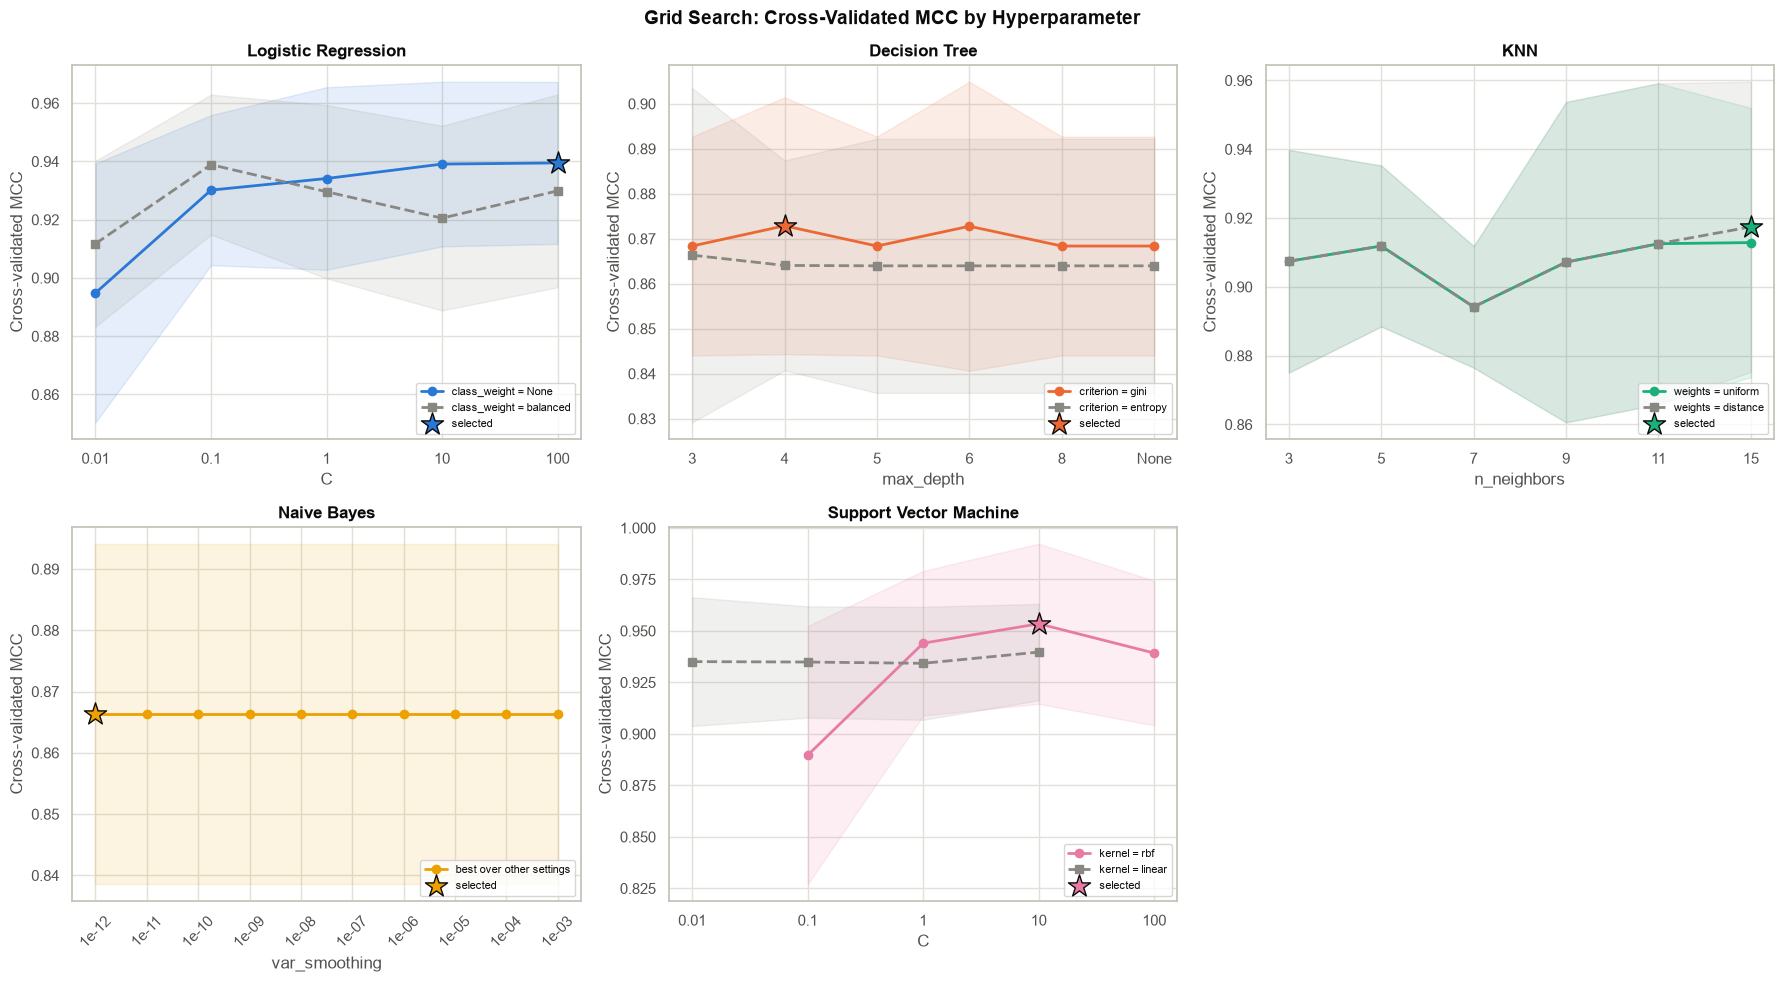

In [28]:
# Hyperparameter on the x axis and the one that splits the lines, per model
TUNING_PLOT_SPEC = {
    "Logistic Regression": ("C", "class_weight"),
    "Decision Tree": ("max_depth", "criterion"),
    "KNN": ("n_neighbors", "weights"),
    "Naive Bayes": ("var_smoothing", None),
    "Support Vector Machine": ("C", "kernel"),
}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, name in zip(axes.ravel(), MODEL_NAMES):
    x_param, line_param = TUNING_PLOT_SPEC[name]
    plot_tuning_curve(ax, searches[name], x_param, line_param, MODEL_COLOUR_MAP[name])
    ax.set_title(name)
# Five models on a 2 x 3 grid leaves one empty panel
axes.ravel()[-1].axis("off")
fig.suptitle("Grid Search: Cross-Validated MCC by Hyperparameter", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## Section 6: Cross-Validated Performance (Training Set)

The test set has only 114 rows, so a single misclassified sample moves accuracy by almost one percentage point. To judge whether differences between models are real or just noise, each tuned model is re-evaluated with 5-fold stratified cross-validation on the training set, and the mean and standard deviation of all six metrics are reported.

These scores use the same folds as the tuning step, so they are slightly optimistic. They are used to compare the models' **stability**, not as final scores; the final scores come from the untouched test set in Section 7.

In [29]:
# The six assignment metrics, computed in every fold
METRIC_NAMES = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
cv_scoring = {
    "Accuracy": "accuracy",
    "AUC": "roc_auc",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "MCC": mcc_scorer,
}


def cross_validate_model(model):
    """Cross-validate a tuned pipeline on the training set.

    Parameters
    ----------
    model : sklearn.pipeline.Pipeline
        Tuned pipeline; it is cloned and refitted inside every fold.

    Returns
    -------
    dict
        Metric name mapped to a numpy array with one score per fold.
    """
    scores = cross_validate(model, X_train, y_train, cv=cv_splitter, scoring=cv_scoring, n_jobs=-1)
    return {metric: scores[f"test_{metric}"] for metric in METRIC_NAMES}


cv_results = {name: cross_validate_model(model) for name, model in best_models.items()}

# Readable table: mean +/- standard deviation for every metric
cv_table = pd.DataFrame({
    name: {metric: f"{folds.mean():.4f} +/- {folds.std():.4f}" for metric, folds in scores.items()}
    for name, scores in cv_results.items()
}).T
display(cv_table)

,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.9714 +/- 0.0132,0.9831 +/- 0.0150,0.9712 +/- 0.0305,0.9529 +/- 0.0235,0.9615 +/- 0.0176,0.9395 +/- 0.0278
Decision Tree,0.9385 +/- 0.0164,0.9423 +/- 0.0193,0.9247 +/- 0.0590,0.9176 +/- 0.0506,0.9181 +/- 0.0187,0.8729 +/- 0.0286
KNN,0.9604 +/- 0.0204,0.9907 +/- 0.0076,0.9943 +/- 0.0114,0.9000 +/- 0.0634,0.9433 +/- 0.0304,0.9174 +/- 0.0422
Naive Bayes,0.9363 +/- 0.0128,0.9877 +/- 0.0032,0.9373 +/- 0.0456,0.8941 +/- 0.0576,0.9126 +/- 0.0189,0.8663 +/- 0.0278
Support Vector Machine,0.9780 +/- 0.0184,0.9957 +/- 0.0045,0.9938 +/- 0.0125,0.9471 +/- 0.0432,0.9694 +/- 0.0259,0.9535 +/- 0.0389


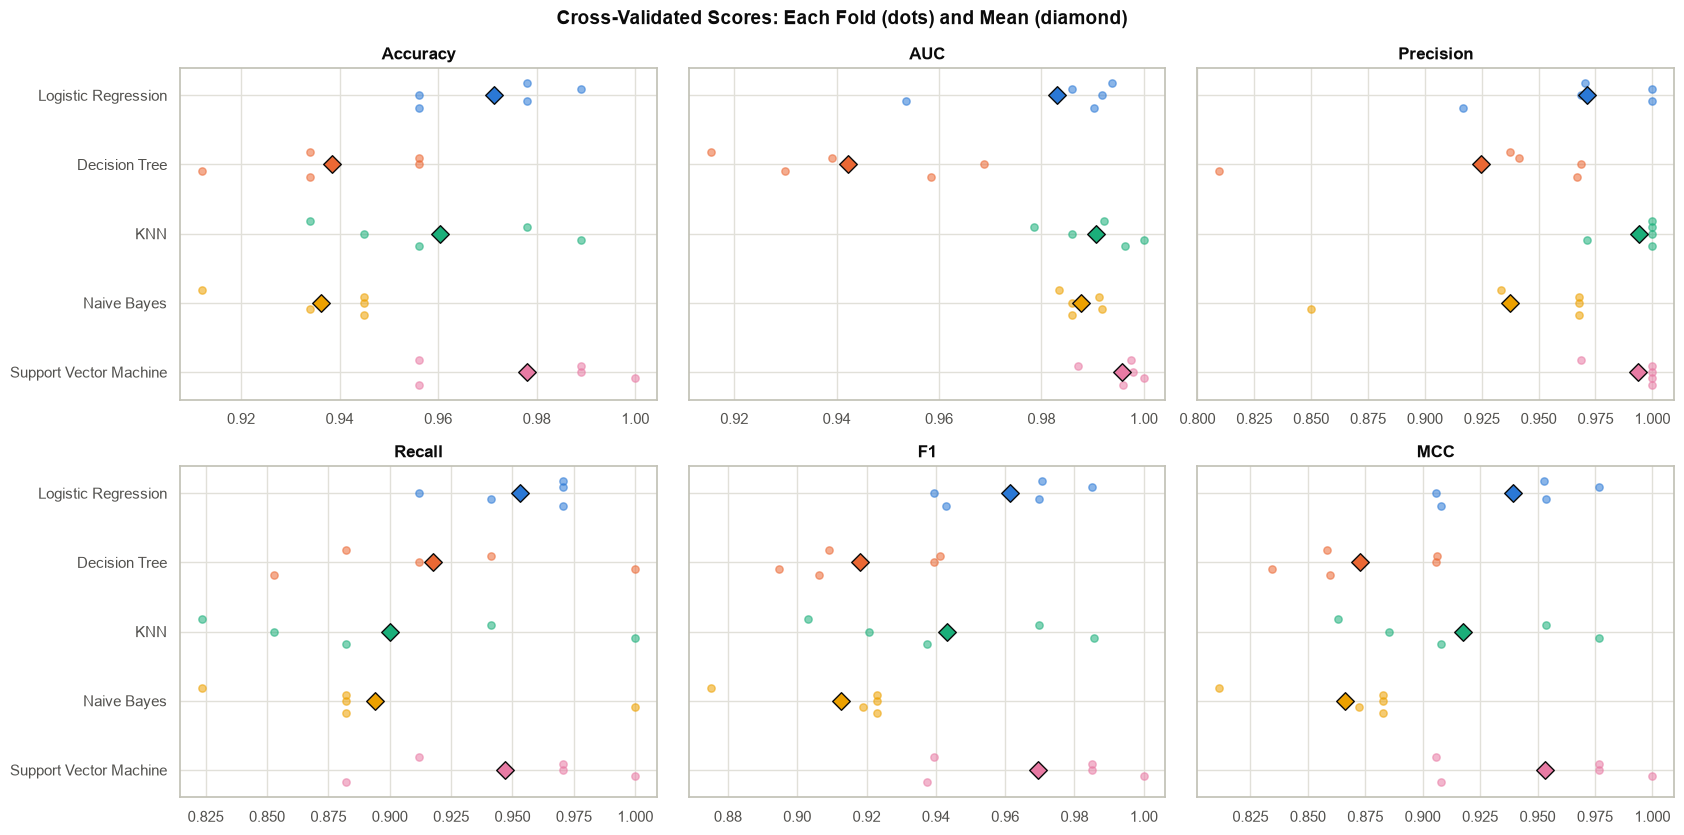

In [30]:
# Score in every fold (dots) and the mean across folds (diamond), for each metric
fold_offsets = np.linspace(-0.18, 0.18, CV_FOLDS)

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), sharey=True)
for ax, metric in zip(axes.ravel(), METRIC_NAMES):
    for position, name in zip(MODEL_POSITIONS, MODEL_NAMES):
        folds = cv_results[name][metric]
        # Small vertical offsets keep identical fold scores from hiding each other
        ax.scatter(folds, position + fold_offsets, s=28, alpha=0.55, color=MODEL_COLOUR_MAP[name])
        ax.scatter(folds.mean(), position, marker="D", s=80, color=MODEL_COLOUR_MAP[name], edgecolor="#0b0b0b", zorder=3)
    ax.set_title(metric)
axes[0, 0].set_yticks(MODEL_POSITIONS, MODEL_NAMES)
axes[0, 0].invert_yaxis()
fig.suptitle("Cross-Validated Scores: Each Fold (dots) and Mean (diamond)", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

**Reading the plot:** a tight cluster of dots means the model behaves consistently across different subsets of the training data; a wide spread means its score depends heavily on which samples it happens to see.

## Section 7: Test Set Evaluation

Each tuned model is evaluated **once** on the held-out test set with a single function, `evaluate_model`. The Streamlit app uses the same logic, so the metrics it displays match this notebook exactly.

- **AUC** is computed from continuous scores, not from hard 0/1 predictions: the predicted probability of malignancy for four of the models, and the decision function (signed distance from the separating boundary) for the SVM. AUC only depends on how the samples are ranked, so both kinds of score are valid. This also avoids `SVC(probability=True)`, which is deprecated from scikit-learn 1.9.
- **Precision, recall and F1** treat malignant (1) as the positive class.
- **MCC** uses the full confusion matrix.

In [31]:
def positive_class_scores(model, X_eval):
    """Return a continuous score for the malignant class, used for AUC and curves.

    Parameters
    ----------
    model : fitted sklearn estimator
        Classifier to score.
    X_eval : pandas.DataFrame
        Features in FEATURE_NAMES order.

    Returns
    -------
    numpy.ndarray
        Predicted probability of malignancy when the model provides
        predict_proba, otherwise the decision function (used by the SVM).
        Higher values always mean "more likely malignant".
    """
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_eval)[:, 1]
    return model.decision_function(X_eval)


def evaluate_model(model, X_eval, y_eval):
    """Compute the six assignment metrics for a fitted classifier.

    Parameters
    ----------
    model : fitted sklearn estimator
        Must implement predict, and either predict_proba or decision_function.
    X_eval : pandas.DataFrame
        Features in FEATURE_NAMES order.
    y_eval : array-like
        True labels encoded as 1 = malignant and 0 = benign.

    Returns
    -------
    dict
        Accuracy, AUC, Precision, Recall, F1 and MCC. Precision, recall
        and F1 treat malignant (1) as the positive class; AUC uses the
        continuous scores from positive_class_scores.
    """
    y_pred = model.predict(X_eval)
    y_score = positive_class_scores(model, X_eval)
    return {
        "Accuracy": accuracy_score(y_eval, y_pred),
        "AUC": roc_auc_score(y_eval, y_score),
        "Precision": precision_score(y_eval, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_eval, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_eval, y_pred, pos_label=1, zero_division=0),
        "MCC": matthews_corrcoef(y_eval, y_pred),
    }


# Evaluate every tuned model on the held-out test set
test_results = pd.DataFrame(
    {name: evaluate_model(model, X_test, y_test) for name, model in best_models.items()}
).T[METRIC_NAMES]
test_results.index.name = "ML Model Name"
display(test_results.round(4))

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9825,0.9957,0.9762,0.9762,0.9762,0.9623
Decision Tree,0.9474,0.9312,0.9737,0.8810,0.9250,0.8872
KNN,0.9561,0.9964,0.9512,0.9286,0.9398,0.9054
Naive Bayes,0.9386,0.9924,0.9487,0.8810,0.9136,0.8675
Support Vector Machine,0.9912,1.0000,0.9767,1.0000,0.9882,0.9814


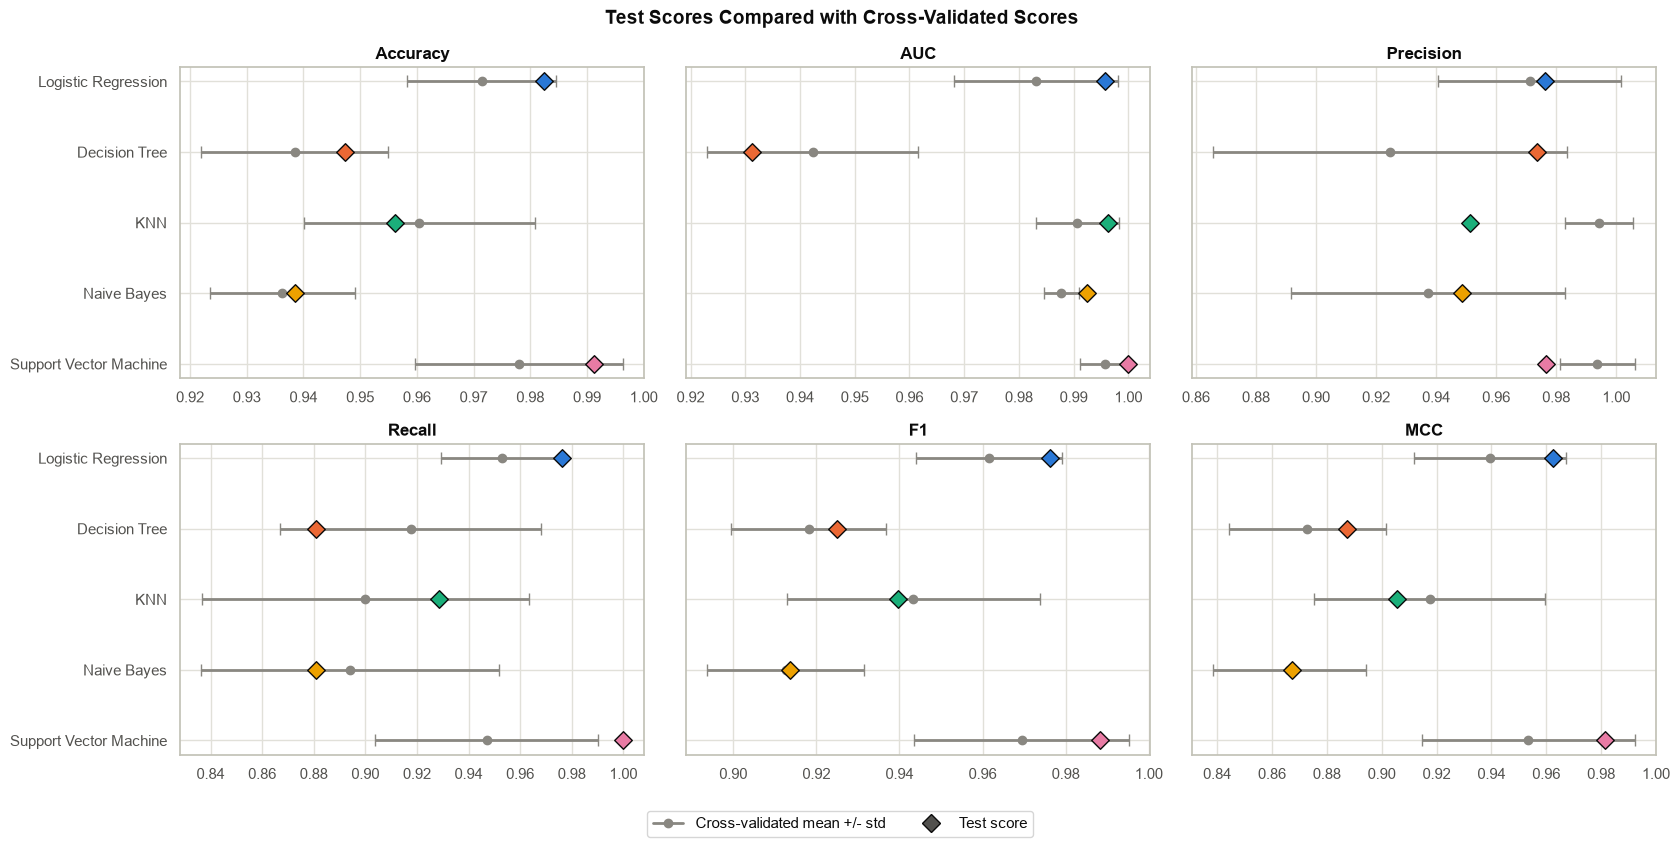

In [32]:
# Test score (diamond) against the cross-validated mean +/- std (grey), for each metric
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), sharey=True)
for ax, metric in zip(axes.ravel(), METRIC_NAMES):
    for position, name in zip(MODEL_POSITIONS, MODEL_NAMES):
        folds = cv_results[name][metric]
        ax.errorbar(
            folds.mean(), position, xerr=folds.std(), fmt="o", markersize=6, capsize=4,
            elinewidth=2, color=NEUTRAL_COLOUR, ecolor=NEUTRAL_COLOUR,
        )
        ax.scatter(
            test_results.loc[name, metric], position, marker="D", s=80,
            color=MODEL_COLOUR_MAP[name], edgecolor="#0b0b0b", zorder=3,
        )
    ax.set_title(metric)
axes[0, 0].set_yticks(MODEL_POSITIONS, MODEL_NAMES)
axes[0, 0].invert_yaxis()

legend_handles = [
    Line2D([0], [0], marker="o", color=NEUTRAL_COLOUR, linewidth=2, label="Cross-validated mean +/- std"),
    Line2D([0], [0], marker="D", linestyle="", markersize=9, markerfacecolor="#52514e",
           markeredgecolor="#0b0b0b", label="Test score"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=2, fontsize=11)
fig.suptitle("Test Scores Compared with Cross-Validated Scores", fontweight="bold", fontsize=14)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

**Reading the plot:** when a test diamond falls inside its grey range, the test result agrees with cross-validation. A diamond far outside the range suggests the 114-row test set happened to be easy or hard for that model.

## Section 8: Diagnostics

The headline metrics are broken down to see where each model goes wrong:

- **Confusion matrices.** Rows are the actual class and columns the prediction. The bottom-left cell counts false negatives (malignant predicted as benign) and the top-right cell counts false positives (benign predicted as malignant).
- **Classification reports.** Precision, recall and F1 for each class separately.
- **ROC and precision-recall curves.** How well each model ranks malignant above benign across all decision thresholds.

In [33]:
def confusion_counts(model, X_eval, y_eval):
    """Return the four confusion matrix counts with malignant as positive.

    Parameters
    ----------
    model : fitted sklearn estimator
        Classifier to evaluate.
    X_eval : pandas.DataFrame
        Features in FEATURE_NAMES order.
    y_eval : array-like
        True labels encoded as 1 = malignant and 0 = benign.

    Returns
    -------
    dict
        TN, FP, FN and TP counts. FN is the number of malignant tumours
        predicted as benign; FP is the number of benign tumours predicted
        as malignant.
    """
    tn, fp, fn, tp = confusion_matrix(y_eval, model.predict(X_eval), labels=[0, 1]).ravel()
    return {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}


# Counts per model, used for the plot titles below and the Section 9.1 evidence table
confusion_table = pd.DataFrame(
    {name: confusion_counts(model, X_test, y_test) for name, model in best_models.items()}
).T

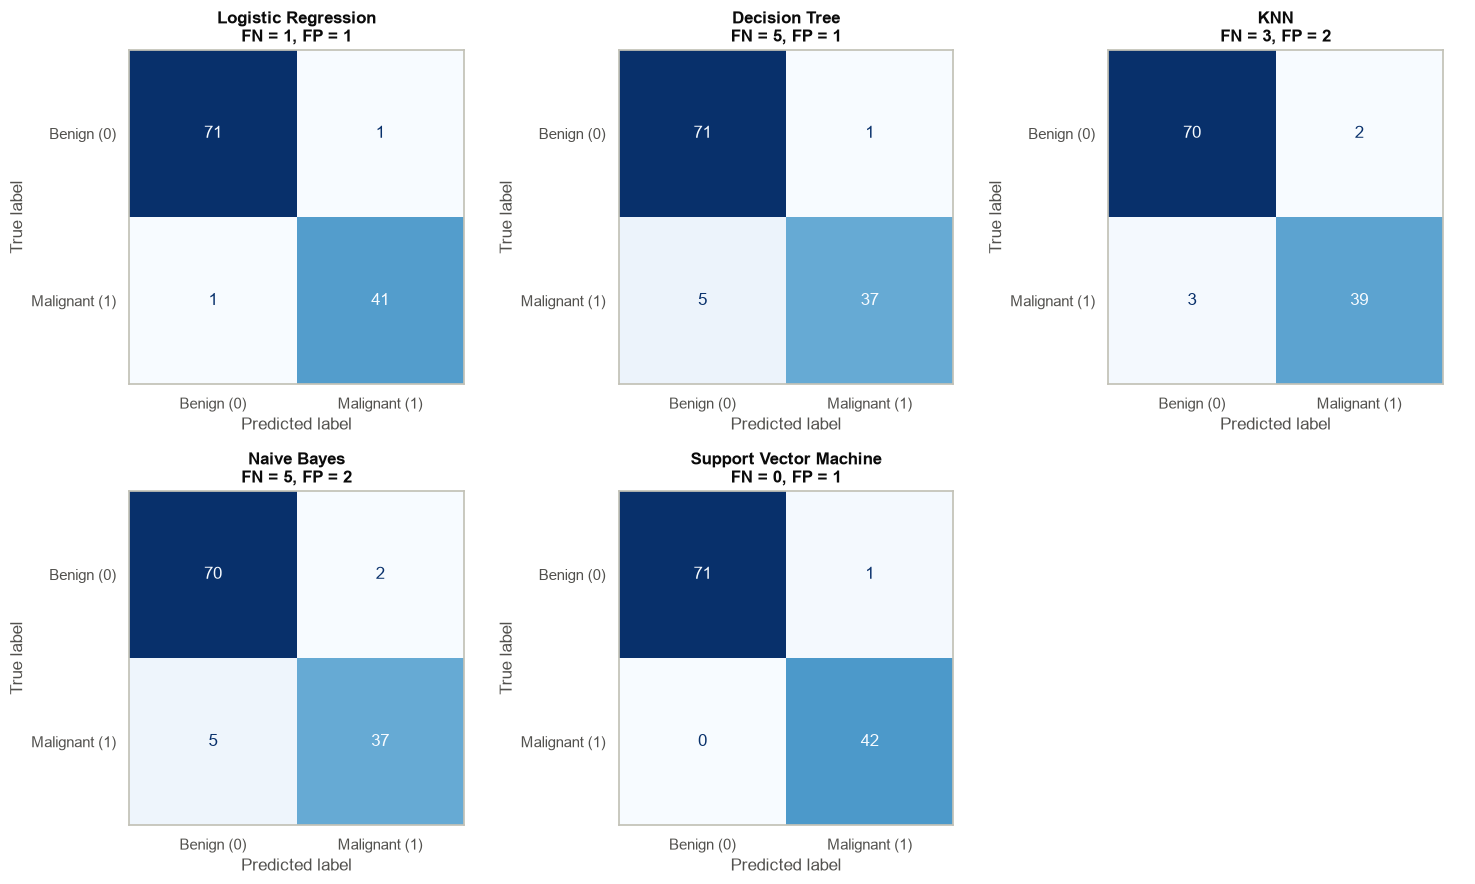

In [34]:
# Confusion matrices: rows are actual classes, columns are predictions
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, model) in zip(axes.ravel(), best_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, labels=[0, 1], display_labels=CLASS_NAMES,
        cmap="Blues", colorbar=False, ax=ax,
    )
    counts = confusion_table.loc[name]
    ax.set_title(f"{name}\nFN = {counts['FN']}, FP = {counts['FP']}")
    ax.grid(False)
# Five models on a 2 x 3 grid leaves one empty panel
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [35]:
# Per-class precision, recall and F1 for every model
for name, model in best_models.items():
    print(name)
    print("-" * len(name))
    print(classification_report(
        y_test, model.predict(X_test), labels=[0, 1], target_names=CLASS_NAMES, digits=4
    ))

Logistic Regression
-------------------
               precision    recall  f1-score   support

   Benign (0)     0.9861    0.9861    0.9861        72
Malignant (1)     0.9762    0.9762    0.9762        42

     accuracy                         0.9825       114
    macro avg     0.9812    0.9812    0.9812       114
 weighted avg     0.9825    0.9825    0.9825       114

Decision Tree
-------------
               precision    recall  f1-score   support

   Benign (0)     0.9342    0.9861    0.9595        72
Malignant (1)     0.9737    0.8810    0.9250        42

     accuracy                         0.9474       114
    macro avg     0.9539    0.9335    0.9422       114
 weighted avg     0.9488    0.9474    0.9468       114

KNN
---
               precision    recall  f1-score   support

   Benign (0)     0.9589    0.9722    0.9655        72
Malignant (1)     0.9512    0.9286    0.9398        42

     accuracy                         0.9561       114
    macro avg     0.9551    0.9504  

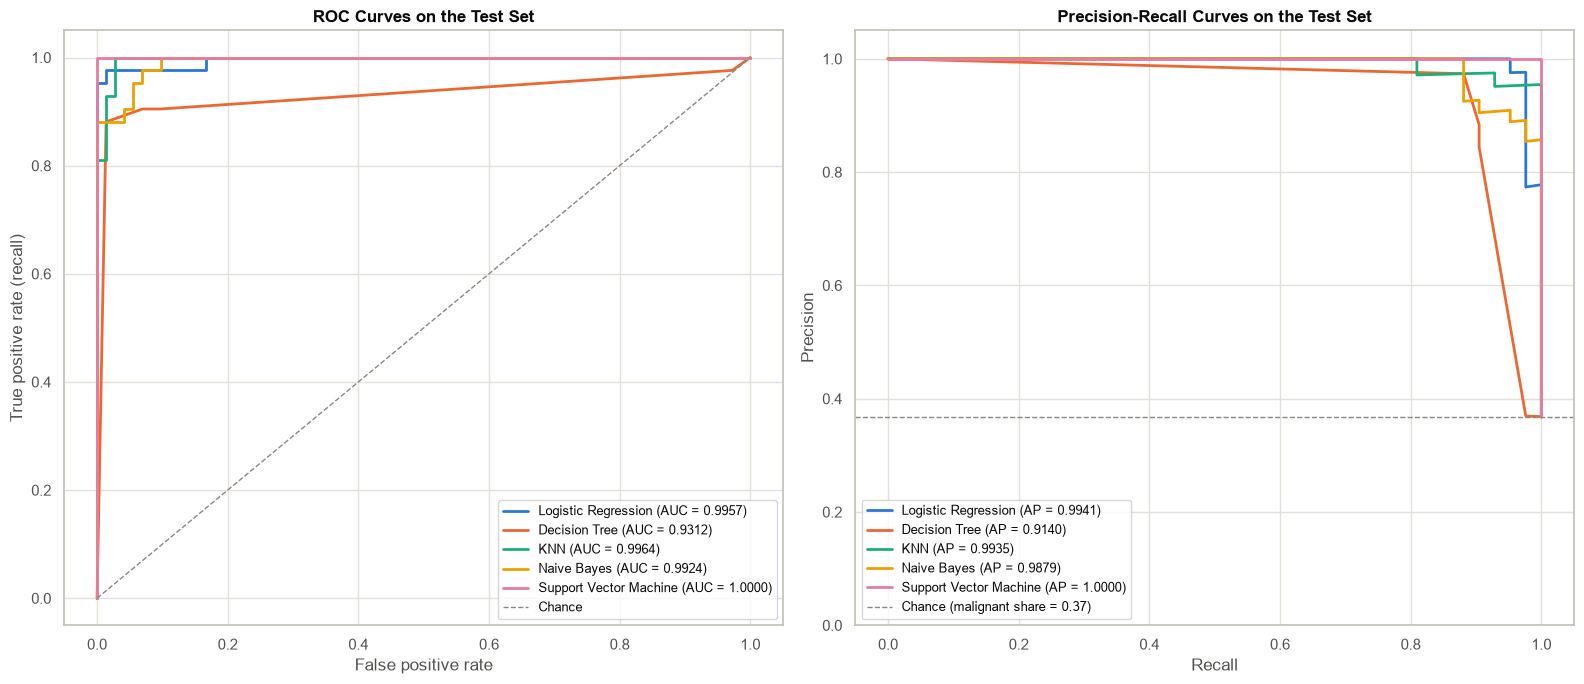

In [36]:
# ROC curves (left) and precision-recall curves (right) on the test set
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for name, model in best_models.items():
    y_score = positive_class_scores(model, X_test)
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, y_score)
    precision_values, recall_values, _ = precision_recall_curve(y_test, y_score)
    axes[0].plot(
        false_positive_rate, true_positive_rate, linewidth=2, color=MODEL_COLOUR_MAP[name],
        label=f"{name} (AUC = {roc_auc_score(y_test, y_score):.4f})",
    )
    axes[1].plot(
        recall_values, precision_values, linewidth=2, color=MODEL_COLOUR_MAP[name],
        label=f"{name} (AP = {average_precision_score(y_test, y_score):.4f})",
    )

# Reference lines: a random classifier on each plot
axes[0].plot([0, 1], [0, 1], linestyle="--", color=NEUTRAL_COLOUR, linewidth=1, label="Chance")
axes[1].axhline(
    y_test.mean(), linestyle="--", color=NEUTRAL_COLOUR, linewidth=1,
    label=f"Chance (malignant share = {y_test.mean():.2f})",
)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC Curves on the Test Set")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves on the Test Set")
axes[1].set_ylim(0, 1.05)
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "lower left", fontsize=9)
plt.tight_layout()
plt.show()

## Section 9: Observations and Model Selection

**Selection rule (fixed before looking at the results):**

1. Highest test MCC. Of the six metrics, MCC is the one that uses all four cells of the confusion matrix, so it rewards getting both classes right and is not inflated by the class imbalance.
2. Ties are broken by the higher cross-validated MCC mean, that is, the model that also performed better on the training folds.

This section has two parts:

- **9.1 Evidence and selection.** The evidence table, the selected model, an overfitting check and the test samples each model gets wrong.
- **9.2 Observations.** The observations table for the README, written from that evidence and the earlier sections.

### 9.1 Evidence and selection

In [37]:
# Evidence table: test metrics, error counts and cross-validation stability
summary = test_results.copy()
summary["FN"] = confusion_table["FN"]
summary["FP"] = confusion_table["FP"]
summary["CV MCC mean"] = [cv_results[name]["MCC"].mean() for name in summary.index]
summary["CV MCC std"] = [cv_results[name]["MCC"].std() for name in summary.index]
display(summary.round(4))

,Accuracy,AUC,Precision,Recall,F1,MCC,FN,FP,CV MCC mean,CV MCC std
ML Model Name,,,,,,,,,,
Logistic Regression,0.9825,0.9957,0.9762,0.9762,0.9762,0.9623,1,1,0.9395,0.0278
Decision Tree,0.9474,0.9312,0.9737,0.8810,0.9250,0.8872,5,1,0.8729,0.0286
KNN,0.9561,0.9964,0.9512,0.9286,0.9398,0.9054,3,2,0.9174,0.0422
Naive Bayes,0.9386,0.9924,0.9487,0.8810,0.9136,0.8675,5,2,0.8663,0.0278
Support Vector Machine,0.9912,1.0000,0.9767,1.0000,0.9882,0.9814,0,1,0.9535,0.0389


#### Selected model 
Applying the rule to the table above, the **Support Vector Machine** has the highest test MCC (0.9814), ahead of Logistic Regression (0.9623), so no tie-break is needed. It also has the highest cross-validated MCC mean (0.9535).

,train,cross-validated,test,train - test
Logistic Regression,0.9890,0.9714,0.9825,0.0066
Decision Tree,0.9802,0.9385,0.9474,0.0329
KNN,1.0000,0.9604,0.9561,0.0439
Naive Bayes,0.9429,0.9363,0.9386,0.0043
Support Vector Machine,0.9868,0.9780,0.9912,-0.0044


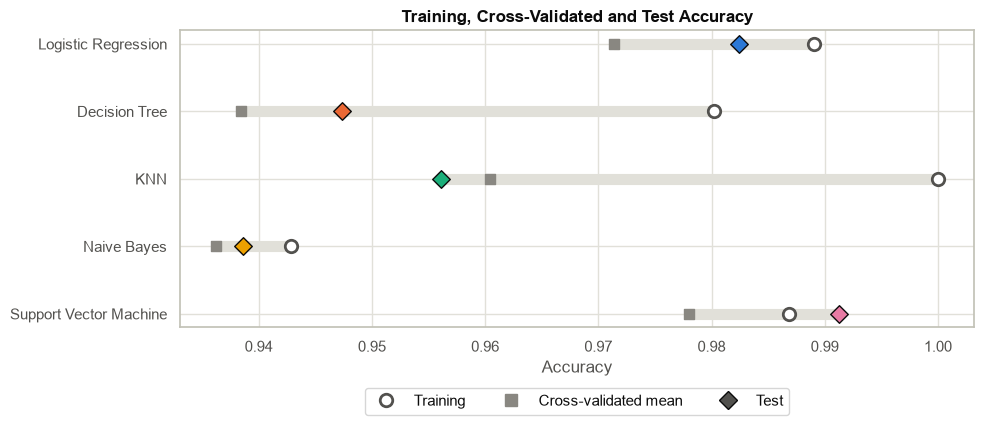

In [38]:
# Overfitting check: training, cross-validated and test accuracy side by side
accuracy_check = pd.DataFrame({
    "train": {name: model.score(X_train, y_train) for name, model in best_models.items()},
    "cross-validated": {name: cv_results[name]["Accuracy"].mean() for name in MODEL_NAMES},
    "test": test_results["Accuracy"],
})
accuracy_check["train - test"] = accuracy_check["train"] - accuracy_check["test"]
display(accuracy_check.round(4))

fig, ax = plt.subplots(figsize=(10, 4.5))
for position, name in zip(MODEL_POSITIONS, MODEL_NAMES):
    row = accuracy_check.loc[name]
    span = row[["train", "cross-validated", "test"]].astype(float)
    # Grey band spanning the three accuracies of one model
    ax.plot([span.min(), span.max()], [position, position], color="#e1e0d9", linewidth=8, solid_capstyle="round", zorder=1)
    ax.scatter(row["train"], position, marker="o", s=80, facecolor="white", edgecolor="#52514e", linewidth=2, zorder=3)
    ax.scatter(row["cross-validated"], position, marker="s", s=60, color=NEUTRAL_COLOUR, zorder=3)
    ax.scatter(row["test"], position, marker="D", s=80, color=MODEL_COLOUR_MAP[name], edgecolor="#0b0b0b", zorder=4)
ax.set_yticks(MODEL_POSITIONS, MODEL_NAMES)
ax.invert_yaxis()
ax.set_xlabel("Accuracy")
ax.set_title("Training, Cross-Validated and Test Accuracy")
ax.legend(
    handles=[
        Line2D([0], [0], marker="o", linestyle="", markersize=9, markerfacecolor="white",
               markeredgecolor="#52514e", markeredgewidth=2, label="Training"),
        Line2D([0], [0], marker="s", linestyle="", markersize=8, color=NEUTRAL_COLOUR, label="Cross-validated mean"),
        Line2D([0], [0], marker="D", linestyle="", markersize=9, markerfacecolor="#52514e",
               markeredgecolor="#0b0b0b", label="Test"),
    ],
    loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3,
)
plt.tight_layout()
plt.show()

**Reading the plot:** a large gap between the open circle (training) and the diamond (test) is a sign of overfitting. KNN's training accuracy of 1.0 is automatic with distance weighting, because every training sample is its own nearest neighbour at distance zero, so it says nothing about overfitting.

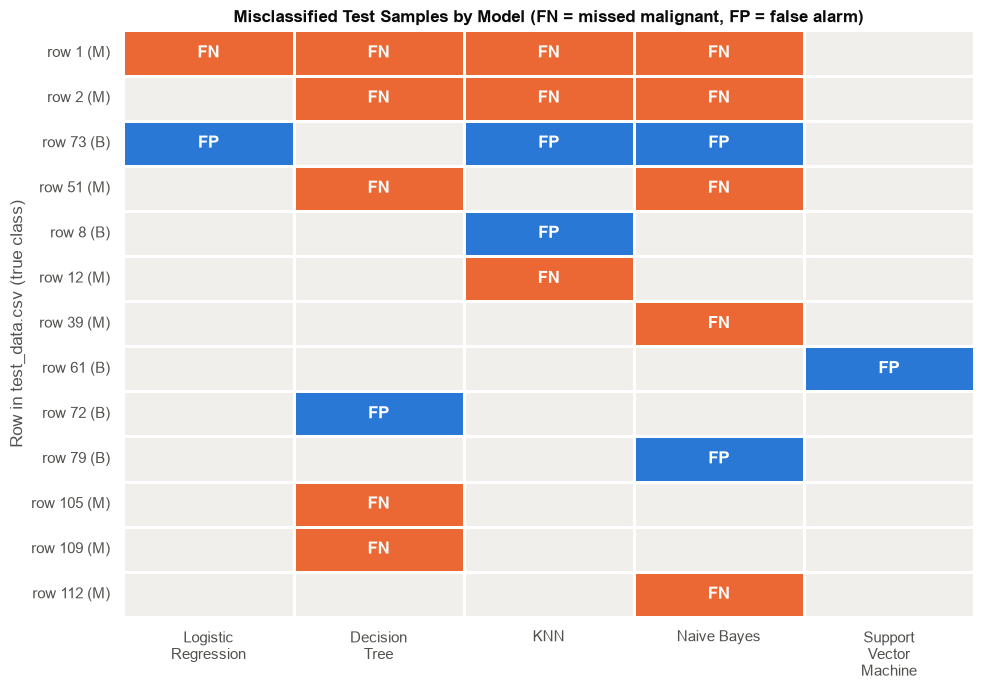

Test samples misclassified by at least one model: 13
Hardest malignant sample: row 1, missed by 4 of 5 models; the SVM classifies it correctly.


In [39]:
# Which test samples each model gets wrong: FN = missed malignant, FP = false alarm
test_predictions = {name: model.predict(X_test) for name, model in best_models.items()}
y_test_values = y_test.values

error_labels = pd.DataFrame({
    name: np.where(
        (y_test_values == 1) & (predictions == 0), "FN",
        np.where((y_test_values == 0) & (predictions == 1), "FP", ""),
    )
    for name, predictions in test_predictions.items()
})
# Keep the test rows that at least one model gets wrong, most-missed first
error_labels = error_labels[(error_labels != "").any(axis=1)]
models_wrong = (error_labels != "").sum(axis=1).sort_values(ascending=False, kind="stable")
error_labels = error_labels.loc[models_wrong.index]
error_codes = error_labels.apply(lambda column: column.map({"": 0, "FN": 1, "FP": 2}))
row_labels = [f"row {position} ({INVERSE_LABEL_MAP[y_test_values[position]]})" for position in error_labels.index]

fig, ax = plt.subplots(figsize=(10, 0.42 * len(error_labels) + 1.6))
sns.heatmap(
    error_codes, annot=error_labels.values, fmt="", cbar=False, vmin=0, vmax=2,
    cmap=ListedColormap(["#f0efec", CLASS_COLOURS["M"], CLASS_COLOURS["B"]]),
    linewidths=2, linecolor="white", annot_kws={"color": "white", "fontweight": "bold"}, ax=ax,
)
ax.set_xticklabels([textwrap.fill(name, 12) for name in error_labels.columns], rotation=0)
ax.set_yticklabels(row_labels, rotation=0)
ax.set_ylabel("Row in test_data.csv (true class)")
ax.set_title("Misclassified Test Samples by Model (FN = missed malignant, FP = false alarm)")
plt.tight_layout()
plt.show()

# The malignant sample missed by the most models
prediction_frame = pd.DataFrame(test_predictions)
models_missing_each = (prediction_frame.loc[y_test_values == 1] == 0).sum(axis=1)
hardest_row = int(models_missing_each.idxmax())
hardest_missed_by = int(models_missing_each.max())
svm_catches_hardest = bool(prediction_frame.loc[hardest_row, "Support Vector Machine"] == 1)
print(f"Test samples misclassified by at least one model: {len(error_labels)}")
print(
    f"Hardest malignant sample: row {hardest_row}, missed by {hardest_missed_by} of {len(MODEL_NAMES)} models; "
    f"the SVM classifies it {'correctly' if svm_catches_hardest else 'incorrectly'}."
)

**Reading the plot:** each row is a test sample that at least one model misclassifies, and each column is a model. Row numbers count the data rows of `test_data.csv` from 0, not including the header. Rows shared by several models are the hard cases in the overlap region between the classes; errors made by a single model point to that model's own weakness.

### 9.2 Observations

Written from the evidence in Section 9.1 and the earlier sections. This table goes into the README as it is.

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Second best on test MCC (0.9623), with accuracy 0.9825 and AUC 0.9957: 1 false negative and 1 false positive out of 114 test samples. The classes are almost linearly separable (Section 2.3), so a single linear boundary captures most of the signal, and tuning preferred weak regularisation (C = 100). Its cross-validated MCC (0.9395 +/- 0.0278) varies less from fold to fold than that of the SVM or KNN, so it is the most predictable of the top three models. The trade-off is interpretability: radius, perimeter and area are near duplicates of each other (Section 2.1), so the model has to split their combined effect across several correlated coefficients. Individual coefficients therefore cannot be read as the effect of one feature, even though the combined prediction is accurate. |
| Decision Tree | Fourth on test MCC (0.8872) and the lowest AUC of all models (0.9312). Tuning chose a shallow tree (max_depth = 4, min_samples_leaf = 2); a tree of depth 4 has at most 16 leaves, so it can output only a few distinct probabilities, and this coarse ranking produces its step-like ROC curve (Section 8) and low AUC. It missed 5 of the 42 malignant test samples (recall 0.8810) while raising 1 false alarm. Training accuracy (0.9802) is well above its cross-validated (0.9385) and test (0.9474) accuracy, and its cross-validated precision varies the most of all models (+/- 0.0590), both signs of high variance. Its tuning curve (Section 5.1) is almost flat across depths, so the limit is the axis-aligned splits themselves: the class boundary is oblique, and a shallow tree can only approximate it with a few steps. |
| KNN | Third on test MCC (0.9054): 3 false negatives and 2 false positives. Tuning chose a large neighbourhood (k = 15) with distance weighting and Euclidean distance. Its ranking of samples is excellent (AUC 0.9964), but its hard predictions lean towards benign: it has the highest cross-validated precision of all models (0.9943) and the most variable cross-validated recall (0.9000 +/- 0.0634). Two of its three missed malignant samples are also missed by the Decision Tree and Naive Bayes (Section 9.1), which places them in the overlap region between the classes, where benign neighbours, the majority class, can outvote them. Scaling puts all features on the same range, but the redundant size features still count several times in the distance, which dilutes the contribution of the other characteristics. |
| Naive Bayes | Lowest test MCC (0.8675) and accuracy (0.9386): 5 false negatives and 2 false positives. Its assumptions fit this dataset poorly: the features are strongly correlated (15 pairs above 0.95) rather than independent, and several are right-skewed rather than Gaussian. Treating correlated features as independent evidence counts the same size information several times, which distorts its probability estimates. Its training accuracy (0.9429) is barely above its test accuracy (Section 9.1), so its errors come from bias in its assumptions rather than from overfitting, and tuning var_smoothing made no difference to its score (Section 5.1). Its AUC (0.9924) is still high, so it ranks samples well; it is fast and simple, but the decisions it makes at the default threshold are the least accurate of the five models. |
| Support Vector Machine | Best on all six test metrics: accuracy 0.9912, AUC 1.0000, recall 1.0000 and MCC 0.9814, with no missed malignant samples and 1 false positive. Tuning chose an RBF kernel with C = 10 and gamma = 0.01, lower than the default gamma (about 0.033 for 30 standardised features), which gives a smooth, gently curved boundary; this suits classes that are almost linearly separable (Section 2.3), and the linear kernel was close behind in the tuning curves (Section 5.1). It is also the only model that correctly classifies the malignant test sample missed by the other four. Its test MCC is above its cross-validated MCC (0.9535 +/- 0.0389), so the perfect test recall partly reflects a favourable split; its cross-validated recall of 0.9471 is a more realistic expectation for new data. |
| Overall, Winner for your dataset? | Support Vector Machine. It has the highest test MCC (0.9814), which is the selection rule, and also the highest cross-validated MCC (0.9535), so both criteria agree. The ranking by test MCC (Support Vector Machine, Logistic Regression, KNN, Decision Tree, Naive Bayes) is the same as the ranking by cross-validated MCC, so the order is not an artefact of one test split. Logistic Regression is a close runner-up: it made only one more error on the test set, and the gap in cross-validated MCC (0.0140) is smaller than either model's fold-to-fold spread. It would be a reasonable choice where a simpler linear model is preferred. |

## Section 10: Saving and Verifying Artifacts

Each tuned pipeline (scaler plus classifier) is saved to `model/` with joblib, together with a small registry file that tells the app which file belongs to which model.

The verification step then reproduces exactly what the Streamlit app will do, using only files on disk: load each model, read `test_data.csv`, reorder its columns to `FEATURE_NAMES`, encode the labels with `LABEL_MAP` and recompute the metrics with no fitting. The results must match Section 7. This catches column order, label mapping and file path problems before the app is built.

In [40]:
# File name of each model inside model/
MODEL_FILES = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib",
}

for name, model in best_models.items():
    path = MODEL_DIR / MODEL_FILES[name]
    joblib.dump(model, path)
    print(f"Saved {name:<24} to {path.as_posix():<30} {path.stat().st_size / 1024:8.1f} KB")

# Registry used by the app to build its model dropdown
save_json(
    {"models": MODEL_FILES, "trained_with": ENV_VERSIONS},
    MODEL_DIR / "model_registry.json",
)
print("Saved model/model_registry.json")

Saved Logistic Regression      to model/logistic_regression.joblib      3.0 KB
Saved Decision Tree            to model/decision_tree.joblib          4.8 KB
Saved KNN                      to model/knn.joblib                  112.9 KB
Saved Naive Bayes              to model/naive_bayes.joblib            3.6 KB
Saved Support Vector Machine   to model/svm.joblib                   17.7 KB
Saved model/model_registry.json


In [41]:
def verify_saved_models(test_path, expected_results, tolerance=1e-9):
    """Reproduce the app's workflow from disk and compare it with Section 7.

    Each model is loaded from model/, the test CSV is read and its columns
    are reordered to FEATURE_NAMES, the labels are encoded with LABEL_MAP,
    and the six metrics are recomputed without any fitting.

    Parameters
    ----------
    test_path : pathlib.Path
        Location of test_data.csv.
    expected_results : pandas.DataFrame
        Test metrics from Section 7, one row per model.
    tolerance : float, default 1e-9
        Absolute tolerance for the comparison.

    Returns
    -------
    pandas.DataFrame
        One row per model with the recomputed metrics and a status column
        that reads PASS or FAIL.
    """
    uploaded = pd.read_csv(test_path)
    missing_columns = set(FEATURE_NAMES + [TARGET]) - set(uploaded.columns)
    assert not missing_columns, f"Test file is missing columns: {sorted(missing_columns)}"
    X_check = uploaded[FEATURE_NAMES]
    y_check = uploaded[TARGET].map(LABEL_MAP)

    rows = {}
    for name, file_name in MODEL_FILES.items():
        loaded_model = joblib.load(MODEL_DIR / file_name)
        metrics = evaluate_model(loaded_model, X_check, y_check)
        recomputed = [metrics[metric] for metric in METRIC_NAMES]
        expected = expected_results.loc[name, METRIC_NAMES].values.astype(float)
        status = "PASS" if np.allclose(recomputed, expected, atol=tolerance) else "FAIL"
        rows[name] = {**{metric: round(metrics[metric], 4) for metric in METRIC_NAMES}, "status": status}
    return pd.DataFrame(rows).T


# Run the check; any FAIL stops the notebook here
verification = verify_saved_models(TEST_DATA_PATH, test_results)
display(verification)
assert (verification["status"] == "PASS").all(), "Saved models do not reproduce the Section 7 results"
print("All saved models reproduce the Section 7 results from disk.")

,Accuracy,AUC,Precision,Recall,F1,MCC,status
Logistic Regression,0.9825,0.9957,0.9762,0.9762,0.9762,0.9623,PASS
Decision Tree,0.9474,0.9312,0.9737,0.881,0.925,0.8872,PASS
KNN,0.9561,0.9964,0.9512,0.9286,0.9398,0.9054,PASS
Naive Bayes,0.9386,0.9924,0.9487,0.881,0.9136,0.8675,PASS
Support Vector Machine,0.9912,1.0,0.9767,1.0,0.9882,0.9814,PASS


All saved models reproduce the Section 7 results from disk.


## Section 11: Wrap-Up

`requirements.txt` is written with the exact library versions of this environment, so that Streamlit Community Cloud installs the same scikit-learn that trained the models. Streamlit itself is pinned only if it is installed here. When deploying, choose the Python version printed below in the app's advanced settings, and check the build log on the first deploy; if pip reports a conflict between streamlit and one of the pinned packages, relax that single pin.

The final cell lists every file the GitHub repository needs from this notebook.

In [42]:
def build_requirements(versions):
    """Create pinned requirements.txt content for Streamlit Community Cloud.

    ucimlrepo is not listed because the app reads test_data.csv and never
    downloads the dataset.

    Parameters
    ----------
    versions : dict
        Output of get_environment_versions.

    Returns
    -------
    str
        One requirement per line, ending with a newline.
    """
    try:
        import streamlit

        streamlit_line = f"streamlit=={streamlit.__version__}"
    except ImportError:
        streamlit_line = "streamlit"
    packages = ["scikit-learn", "pandas", "numpy", "matplotlib", "seaborn", "joblib"]
    lines = [streamlit_line] + [f"{package}=={versions[package]}" for package in packages]
    return "\n".join(lines) + "\n"


# Write requirements.txt at the repository root, next to this notebook
requirements_text = build_requirements(ENV_VERSIONS)
REQUIREMENTS_PATH.write_text(requirements_text, encoding="utf-8")
print(requirements_text)
print(f"Python version to select on Streamlit Community Cloud: {ENV_VERSIONS['python'].rsplit('.', 1)[0]}")

streamlit==1.66.1
scikit-learn==1.9.1
pandas==3.1.0
numpy==2.4.6
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0

Python version to select on Streamlit Community Cloud: 3.11


In [43]:
# Inventory of the files the GitHub repository needs from this notebook
expected_files = [
    TEST_DATA_PATH,
    REQUIREMENTS_PATH,
    MODEL_DIR / "feature_names.json",
    MODEL_DIR / "label_map.json",
    MODEL_DIR / "best_params.json",
    MODEL_DIR / "model_registry.json",
] + [MODEL_DIR / file_name for file_name in MODEL_FILES.values()]

inventory = pd.DataFrame(
    {
        "exists": [path.exists() for path in expected_files],
        "size (KB)": [round(path.stat().st_size / 1024, 1) if path.exists() else None for path in expected_files],
    },
    index=[path.as_posix() for path in expected_files],
)
display(inventory)
assert inventory["exists"].all(), "Some artifacts are missing"
print("All artifacts are in place.")

,exists,size (KB)
test_data.csv,True,24.2
requirements.txt,True,0.1
model/feature_names.json,True,0.6
model/label_map.json,True,0.1
model/best_params.json,True,0.5
model/model_registry.json,True,0.4
model/logistic_regression.joblib,True,3.0
model/decision_tree.joblib,True,4.8
model/knn.joblib,True,112.9
model/naive_bayes.joblib,True,3.6


All artifacts are in place.
